
# Objetivos de Aprendizaje

### 1. Dominio de Patrones de Razonamiento y Orquestación Agéntica

- **Comprender y diseñar arquitecturas de ejecución avanzada:** Desde el ciclo básico de razonamiento y actuación (*ReAct*) hasta flujos secuenciales deterministas (*Pipelines*) y topologías complejas centralizadas en estrella (*Manager Agent Pattern*), logrando que los sistemas descompongan problemas globales, deleguen subtareas y evalúen resultados de manera adaptativa.

### 2. Integración Tipada y Confiabilidad con Tipos Estrictos

- **Eliminar las ambigüedades estocásticas mediante contratos de datos:** Implementar validación estricta de esquemas y tipos en tiempo de ejecución utilizando **Pydantic v2** y capacidades nativas de salidas estructuradas, asegurando una comunicación limpia y sin errores de parseo entre el modelo de lenguaje y las herramientas *downstream*.

### 3. Interoperabilidad Empresarial y Protocolos Estándar

- **Desvincular la lógica del agente de la infraestructura subyacente:** Aplicar los principios del **Model Context Protocol (MCP)** y técnicas avanzadas de *Function Calling* para separar la gestión de recursos de solo lectura y las operaciones transaccionales de escritura, facilitando la escalabilidad y el mantenimiento de los microservicios corporativos.

### 4. Seguridad, Control de Accesos y Resiliencia Transaccional

- **Blindar los sistemas ante operaciones con efectos secundarios (*side-effects*):** Incorporar controles de acceso basados en roles (**RBAC**), salvaguardas de precondiciones, manejo robusto de excepciones y **claves de idempotencia** para prevenir fallos catastróficos, dobles ejecuciones o brechas de cumplimiento normativo (*compliance*).

### 5. Optimización de Recursos, Latencia y Economía de Tokens

- **Garantizar la viabilidad operativa y financiera en producción:** Mitigar el crecimiento descontrolado del contexto (*Context Bloat*) mediante la implementación de límites estrictos de iteraciones, estrategias de poda de historial (*sliding windows*) y selección heterogénea de modelos según la criticidad de la tarea.

### 6. Observabilidad y Trazabilidad Auditable

- **Superar el problema de la «caja negra» en entornos de IA:** Diseñar mecanismos de registro cronológico inmutable (*Event Sourcing* y *Audit Trails*) que permitan auditar los procesos de razonamiento, inspeccionar las trazas de ejecución y cumplir con los requisitos de transparencia para sistemas empresariales críticos.


#Agentes, Arquitectura ReAct y Ciclo Básico de Razonamiento

## Análisis de Requerimientos y Descomposición Agéntica
En la ingeniería de soluciones de Inteligencia Artificial, la transformación de un requerimiento no estructurado $R$ en un plan ejecutable exige la descomposición del problema en una secuencia discreta de sub-objetivos $T = \{t_1, t_2, \dots, t_n\}$.

El agente clasifica e invoca herramientas según la naturaleza de la operación:
* **Herramientas de Consulta (*Read-only*):** Operaciones idempotentes sin efectos secundarios sobre el sistema de origen (ej. lecturas de base de datos o APIs de consulta).
* **Herramientas de Escritura (*Side-effecting*):** Operaciones que mutan persistentemente el estado del entorno (ej. registros en BD, transacciones financieras o peticiones HTTP `POST`/`PUT`).

## Ciclo ReAct (Reason + Act) y Evaluación Adaptativa
Formulado por Yao et al. (2022), el patrón **ReAct** entrelaza trazas de razonamiento explícito (*Thought*) con ejecuciones estructuradas de herramientas (*Action*) y la retroalimentación enviada por el entorno (*Observation*).

Regla fundamental de orquestación agéntica:
> *"Aplica una estrategia de razonamiento (como ReAct) para que el agente evalúe el resultado de una herramienta antes de proceder al siguiente paso."*

Para garantizar la solidez en entornos empresariales, no se utilizan parsers basados en expresiones regulares simples; se definen esquemas con **Pydantic** (`pydantic.BaseModel`) vinculados nativamente al modelo mediante **Function Calling** / **Tool Binding**.

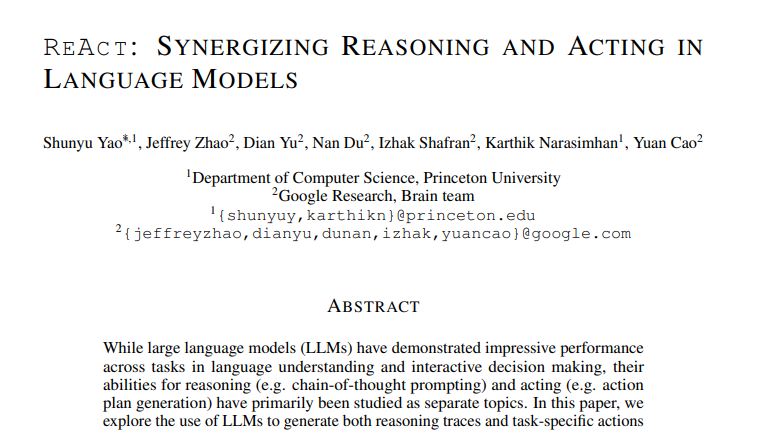

In [1]:
!pip install -qU langchain-google-genai langchain

In [4]:
# =============================================================================
# MÓDULO 1: Fundamentos de Agentes, Arquitectura ReAct y Ciclo Básico de Razonamiento
# Configuración con Google Gemini y Google Colab Userdata
# =============================================================================

# Importamos el módulo os para la gestión de variables de entorno del sistema
import os

# Importamos módulo nativo para formatear y serializar respuestas JSON
import json

# Importamos el gestor de secretos de Google Colab para recuperar credenciales de forma segura
from google.colab import userdata

# Importamos la metaclase Type de typing para tipados especiales permitidos
from typing import Type

# Importamos BaseModel y Field de Pydantic v2 para esquemas y validación estricta
from pydantic import BaseModel, Field

# Importamos la clase base para la construcción de herramientas personalizadas en LangChain
from langchain_core.tools import BaseTool

# Importamos clases de mensajes para estructurar el historial conversacional del agente
from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage

# Importamos el conector oficial de LangChain para modelos generativos de Google Gemini
from langchain_google_genai import ChatGoogleGenerativeAI


# -----------------------------------------------------------------------------
# 0. Configuración de Credenciales del Entorno
# -----------------------------------------------------------------------------

def configurar_credenciales() -> bool:
    """
    Intenta recuperar la API Key de Google desde los secretos de Colab (userdata)
    y configurarla como variable de entorno global.
    """
    try:
        # Extrae el secreto 'GOOGLE_API_KEY' y lo asigna al entorno del sistema operativo
        os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')
        print(" Credenciales de Google API configuradas exitosamente.")
        return True
    except Exception as error:
        # Captura cualquier excepción de ausencia de secreto o fallo en Colab
        print(f"X Error al cargar credenciales: {error}")
        return False


# -----------------------------------------------------------------------------
# 1. Definición de Esquemas Tipados con Pydantic v2 (Tipos Nativos de Python)
# -----------------------------------------------------------------------------

class ConsultaInventarioInput(BaseModel):
    """
    Esquema de validación estricta para la herramienta de consulta de inventario.
    """
    # Campo obligatorio para el SKU del producto con descripción técnica para el LLM
    sku: str = Field(..., description="Código SKU único del producto a consultar en el inventario.")


class RegistroOrdenInput(BaseModel):
    """
    Esquema de validación estricta para la herramienta de escritura transaccional.
    """
    # Campo obligatorio para el código SKU del producto sobre el cual generar la orden
    sku: str = Field(..., description="Código SKU único del producto sobre el cual generar la orden.")
    # Campo numérico entero con validación estricta mayor a cero (gt=0)
    cantidad: int = Field(..., gt=0, description="Cantidad exacta de unidades a ordenar. Debe ser un entero positivo.")


# -----------------------------------------------------------------------------
# 2. Definición de Herramientas Estructuradas (Read-only vs Side-effecting)
# -----------------------------------------------------------------------------

class ConsultaInventarioTool(BaseTool):
    """
    Herramienta de consulta idempotente (Read-only) heredada de BaseTool de LangChain.
    """
    # Nombre único identificador de la herramienta para el motor de Function Calling
    name: str = "consultar_estado_inventario"
    # Descripción técnica detallada para guiar al modelo en su uso operacional
    description: str = "Retorna la disponibilidad actual de stock para un SKU dado sin alterar el estado."
    # Vinculación del esquema Pydantic v2 para la validación automática de parámetros
    args_schema: Type[BaseModel] = ConsultaInventarioInput

    def _run(self, sku: str) -> str:
        """
        Ejecución síncrona de la lógica de negocio de consulta.
        """
        # Base de datos simulada en memoria que representa la persistencia del sistema
        base_datos = {
            "SKU-100": {"nombre": "Servidor Rack 1U", "stock": 5},
            "SKU-200": {"nombre": "Switch Gestionable 24p", "stock": 0}
        }
        # Evaluación condicional determinista para recuperar la entidad solicitada
        if sku in base_datos:
            return json.dumps({"status": "OK", "data": base_datos[sku]})
        return json.dumps({"status": "ERROR", "mensaje": f"El SKU '{sku}' no existe en el inventario."})


class RegistrarOrdenTool(BaseTool):
    """
    Herramienta de escritura (Side-effecting) que muta el estado persistente del sistema.
    """
    # Nombre único identificador de la herramienta de modificación transaccional
    name: str = "registrar_orden_compra"
    # Descripción funcional indicando que altera el estado del entorno
    description: str = "Registra una orden de compra en el sistema alterando los registros de inventario."
    # Vinculación del esquema Pydantic v2 para validación previa a la ejecución
    args_schema: Type[BaseModel] = RegistroOrdenInput

    def _run(self, sku: str, cantidad: int) -> str:
        """
        Ejecución síncrona de la lógica de escritura transaccional.
        """
        # Retorno de la transacción completada serializada en formato JSON estándar
        return json.dumps({
            "status": "COMPLETADO",
            "orden_id": "ORD-9982",
            "detalle": f"Transacción exitosa. Se registraron {cantidad} unidades del SKU '{sku}'."
        })


# -----------------------------------------------------------------------------
# 3. Punto de Entrada Principal y Bucle de Orquestación ReAct
# -----------------------------------------------------------------------------

if __name__ == "__main__":
    # Ejecutamos la función de configuración de credenciales en Google Colab
    if configurar_credenciales():
        # Inicialización del modelo de lenguaje Gemini configurado con temperatura estricta (0.0)
        llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite") #, temperature=0)

        # Instanciación de las clases de herramientas desarrolladas
        herramienta_consulta = ConsultaInventarioTool()
        herramienta_escritura = RegistrarOrdenTool()
        lista_herramientas = [herramienta_consulta, herramienta_escritura]

        # Diccionario de indexación para la resolución determinista de llamadas del LLM
        mapa_herramientas = {tool.name: tool for tool in lista_herramientas}

        # Acoplamiento de herramientas al modelo mediante el protocolo nativo de Function Calling
        llm_con_herramientas = llm.bind_tools(lista_herramientas)

        # Definición de directrices de comportamiento para el agente mediante System Prompt
        prompt_sistema = SystemMessage(
            content=(
                "Eres un agente empresarial de gestión de inventarios. "
                "Sigue una estrategia de razonamiento ReAct: "
                "1. Analiza el requerimiento del usuario. "
                "2. Antes de realizar cualquier orden de compra, consulta siempre el inventario disponible. "
                "3. Evalúa adaptativamente la observación devuelta por la herramienta. "
                "4. Si un producto no tiene stock (stock=0), NO intentes realizar la orden sobre ese SKU; "
                "evalúa si hay otros productos mencionados o solicita alternativas. "
                "5. Solo ejecuta herramientas de escritura si has validado previamente el stock."
            )
        )

        # Definición del prompt de entrada emitido por el usuario del sistema
        mensaje_usuario = HumanMessage(
            content="Necesito adquirir 2 unidades del producto SKU-200. Si no está disponible, revisa el SKU-100."
        )

        # Inicialización del vector de historial conversacional (estado mutable del agente)
        historial_mensajes = [prompt_sistema, mensaje_usuario]

        # Variables de control para el ciclo de ejecución iterativa
        agente_activo = True
        iteracion = 1

        # Bucle principal de control para procesar el razonamiento y las llamadas a herramientas
        while agente_activo and iteracion <= 5:
            print(f"\n--- ITERACIÓN DEL AGENTE {iteracion} ---")

            # Invocación sincrónica al modelo Gemini pasando el contexto acumulado de mensajes
            respuesta_llm = llm_con_herramientas.invoke(historial_mensajes)

            # Adición de la respuesta del modelo al registro histórico
            historial_mensajes.append(respuesta_llm)

            # Verificación condicional de si el LLM emitió intenciones de llamada a herramientas
            if respuesta_llm.tool_calls:
                for tool_call in respuesta_llm.tool_calls:
                    nombre_tool = tool_call["name"]
                    args_tool = tool_call["args"]
                    call_id = tool_call["id"]

                    print(f"-> Acción [LLM]: Invocando '{nombre_tool}' con argumentos {args_tool}")

                    # Recuperación de la instancia de la herramienta desde el mapa de indexación
                    herramienta_obj = mapa_herramientas[nombre_tool]

                    # Ejecución de la herramienta invocando la validación integrada de Pydantic v2
                    resultado_ejecucion = herramienta_obj.invoke(args_tool)

                    print(f"<- Observación [Entorno]: {resultado_ejecucion}")

                    # Empaquetamiento de la observación en un ToolMessage para el siguiente ciclo
                    mensaje_observacion = ToolMessage(
                        content=resultado_ejecucion,
                        tool_call_id=call_id
                    )
                    historial_mensajes.append(mensaje_observacion)
            else:
                # Condición de término: el modelo emite texto plano sin llamadas a funciones adicionales
                print(f"\n[RESPUESTA FINAL DEL AGENTE]:\n{respuesta_llm.content}")
                agente_activo = False

            iteracion += 1
    else:
        print("No se pudo iniciar el agente debido a un fallo en las credenciales.")

 Credenciales de Google API configuradas exitosamente.

--- ITERACIÓN DEL AGENTE 1 ---
-> Acción [LLM]: Invocando 'consultar_estado_inventario' con argumentos {'sku': 'SKU-200'}
<- Observación [Entorno]: {"status": "OK", "data": {"nombre": "Switch Gestionable 24p", "stock": 0}}

--- ITERACIÓN DEL AGENTE 2 ---
-> Acción [LLM]: Invocando 'consultar_estado_inventario' con argumentos {'sku': 'SKU-100'}
<- Observación [Entorno]: {"status": "OK", "data": {"nombre": "Servidor Rack 1U", "stock": 5}}

--- ITERACIÓN DEL AGENTE 3 ---
-> Acción [LLM]: Invocando 'registrar_orden_compra' con argumentos {'sku': 'SKU-100', 'cantidad': 2}
<- Observación [Entorno]: {"status": "COMPLETADO", "orden_id": "ORD-9982", "detalle": "Transacci\u00f3n exitosa. Se registraron 2 unidades del SKU 'SKU-100'."}

--- ITERACIÓN DEL AGENTE 4 ---

[RESPUESTA FINAL DEL AGENTE]:
[{'type': 'text', 'text': 'El producto **SKU-200** no se encuentra disponible actualmente en el inventario (stock: 0). Siguiendo sus instrucciones,


Nota: A partir de Python 3.9 (PEP 585), los tipos integrados nativos como `list`, `dict`, `tuple` y `set` admiten subíndices directamente (por ejemplo, `list[str]` o `dict[str, Any]`).

Por lo tanto, importar `List` y `Dict` desde el módulo `typing` es redundante en Python moderno, y **Pydantic v2** procesa los tipos nativos de Python de forma nativa en su motor de validación.

Únicamente elementos específicos del sistema de tipos que no tienen un equivalente directísimo como valor de contenedor general (como `Any`, o metaclases como `Type`) se mantienen, pero las estructuras de colección estándar deben usar la sintaxis nativa.



# Planificación Estática e Introducción al Patrón Plan-and-Execute



### 1. Limitaciones de la Planificación Reactiva y la Miopía Agéntica

En los sistemas basados en modelos de lenguaje analizados en el módulo anterior, el patrón puramente reactivo (ReAct) padece de miopía operacional. Al evaluar las transiciones de estado paso a paso sin un mapa global, el agente carece de capacidad de anticipación ante dependencias circulares, cuellos de botella temporales o la necesidad de paralelizar tareas independientes.

La consecuencia arquitectónica de esta carencia es la aparición de bucles infinitos de razonamiento, la ejecución de llamadas redundantes a herramientas de recuperación y la degradación del contexto cuando el espacio de búsqueda de la solución es amplio.

### 2. El Patrón Plan-and-Execute (Planificación y Ejecución Desacopladas)

Para superar la miopía reactiva, la ingeniería de agentes implementa el patrón **Plan-and-Execute**, donde el flujo de trabajo se desliga formalmente en dos fases secuenciales y diferenciadas:

1. **Fase de Planificación (*Planner*):** Un modelo de lenguaje de alta capacidad recibe el requerimiento global \(R\) y genera un plan estructurado representado como un Grafo Acíclico Dirigido (DAG) o una lista ordenada de tareas atómicas $$
T = \{t_1, t_2, \dots, t_n\}
$$. Cada nodo del plan define explícitamente su objetivo, las herramientas requeridas y los artefactos de salida esperados.

2. **Fase de Ejecución (*Executor*):** Un componente determinista o un agente ejecutor recorre el plan generado, invocando las herramientas correspondientes y actualizando el estado intermedio del sistema sin re-planificar en cada paso a menos que ocurra una excepción crítica.


In [6]:
# =============================================================================
# MÓDULO 2: Planificación Structured Output y Generación de Esquemas con Pydantic v2

# =============================================================================

# Importamos el módulo os para la gestión de variables de entorno del sistema
import os

# Importamos módulo nativo para formatear respuestas JSON en consola
import json

# Importamos el gestor de secretos de Google Colab para recuperar credenciales de forma segura
from google.colab import userdata

# Importamos únicamente los tipos especiales de typing que no son colecciones estándar de Python
from typing import Any, Type

# Importamos la base de validación y campos de Pydantic v2
from pydantic import BaseModel, Field

# Importamos las herramientas nativas y abstracciones de mensajes de LangChain
from langchain_core.tools import BaseTool
from langchain_core.messages import SystemMessage, HumanMessage

# Importamos el conector oficial de LangChain para modelos generativos de Google Gemini
from langchain_google_genai import ChatGoogleGenerativeAI


# -----------------------------------------------------------------------------
# 0. Configuración de Credenciales del Entorno
# -----------------------------------------------------------------------------

def configurar_credenciales() -> bool:
    """
    Intenta recuperar la API Key de Google desde los secretos de Colab (userdata)
    y configurarla como variable de entorno global.
    """
    try:
        # Extrae el secreto 'GOOGLE_API_KEY' y lo asigna al entorno del sistema operativo
        os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')
        print(" Credenciales de Google API configuradas exitosamente.")
        return True
    except Exception as error:
        # Captura cualquier excepción de ausencia de secreto o fallo en Colab
        print(f"X Error al cargar credenciales: {error}")
        return False


# -----------------------------------------------------------------------------
# 1. Definición de Esquemas con Pydantic v2 usando Tipos Nativos (PEP 585)
# -----------------------------------------------------------------------------

class TareaPlan(BaseModel):
    """
    Esquema Pydantic que representa una tarea individual estructurada dentro del plan.
    """
    # Identificador entero para mantener el orden secuencial
    id_tarea: int = Field(
        ...,
        description="Identificador numérico y secuencial de la tarea (ej. 1, 2, 3)."
    )
    # Descripción detallada de lo que la herramienta o acción debe lograr
    descripcion: str = Field(
        ...,
        description="Explicación precisa del objetivo o acción que realiza esta tarea."
    )
    # Nombre estricto de la herramienta requerida para ejecutar la tarea
    herramienta_sugerida: str = Field(
        ...,
        description="Nombre exacto de la herramienta que debe utilizarse para esta etapa."
    )


class PlanGlobalInput(BaseModel):
    """
    Esquema global que valida la respuesta estructurada completa generada por el LLM.
    Utilizamos la sintaxis nativa `list[...]` en lugar de `typing.List[...]`.
    """
    # Objetivo general derivado de la petición del usuario
    objetivo_global: str = Field(
        ...,
        description="Resumen analítico del objetivo principal que se resolverá."
    )
    # Lista estructurada de subtareas utilizando el tipo nativo list[TareaPlan]
    pasos: list[TareaPlan] = Field(
        ...,
        description="Lista ordenada secuencialmente con los pasos necesarios para completar el objetivo."
    )


# -----------------------------------------------------------------------------
# 2. Definición de Herramientas Personalizadas Heredando de BaseTool
# -----------------------------------------------------------------------------

class HerramientaBusquedaInput(BaseModel):
    """
    Esquema de entrada para validar los argumentos enviados a la herramienta de búsqueda.
    """
    query: str = Field(..., description="Término o frase clave que se buscará.")


class HerramientaBusquedaWeb(BaseTool):
    """
    Herramienta personalizada que simula una búsqueda en la web.
    """
    # Nombre identificador que utilizará el LLM
    name: str = "busqueda_web"
    # Descripción funcional para que el LLM sepa cuándo invocarla
    description: str = "Útil para buscar información en tiempo real sobre noticias, eventos o datos recientes."
    # Asignación del esquema de validación de argumentos Pydantic v2
    args_schema: Type[BaseModel] = HerramientaBusquedaInput

    def _run(self, query: str) -> str:
        """
        Lógica síncrona de ejecución de la herramienta.
        """
        # Simulamos la respuesta formateada en cadena de texto
        return f"[Resultado simulado para '{query}']: Se encontraron 3 artículos relevantes sobre el tema."


class HerramientaCalculadoraInput(BaseModel):
    """
    Esquema de entrada para validar los argumentos enviados a la calculadora.
    """
    expresion: str = Field(..., description="Expresión matemática válida a evaluar, ej: '15 * 40'.")


class HerramientaCalculadora(BaseTool):
    """
    Herramienta personalizada para resolver operaciones matemáticas.
    """
    name: str = "calculadora"
    description: str = "Útil para resolver operaciones matemáticas o cálculos financieros precisos."
    args_schema: Type[BaseModel] = HerramientaCalculadoraInput

    def _run(self, expresion: str) -> str:
        """
        Lógica síncrona de la calculadora.
        """
        try:
            # Evaluación segura básica de la expresión matemática
            resultado = eval(expresion, {"__builtins__": None}, {})
            return f"[Resultado matemático]: {expresion} = {resultado}"
        except Exception as e:
            return f"Error al evaluar la expresión matemática: {str(e)}"


# -----------------------------------------------------------------------------
# 3. Flujo de Ejecución y Generación de Plan Structured Output
# -----------------------------------------------------------------------------

def generar_plan_de_accion(solicitud_usuario: str) -> PlanGlobalInput | None:
    """
    Configura credenciales, inicializa el modelo Gemini con el esquema Pydantic
    y genera el plan estructurado validado.
    """
    # Verificamos e inicializamos las credenciales de Google
    if not configurar_credenciales():
        print("No se puede generar el plan debido a un fallo en las credenciales.")
        return None

    # Instanciamos el modelo LLM especificado configurando la temperatura en 0 para respuestas deterministas
    llm = ChatGoogleGenerativeAI(
        model="gemini-3.5-flash-lite")


    # Forzamos al modelo a responder exclusivamente siguiendo la estructura de nuestro esquema Pydantic
    llm_estructurado = llm.with_structured_output(PlanGlobalInput)

    # Instanciamos las herramientas para incluir sus nombres en el prompt del sistema
    tool_busqueda = HerramientaBusquedaWeb()
    tool_calculadora = HerramientaCalculadora()

    # Construimos el mensaje de sistema especificando las herramientas disponibles
    system_prompt = SystemMessage(
        content=(
            "Eres un agente planificador experto. Tu trabajo es descomponer la solicitud del usuario "
            "en una secuencia de pasos lógicos y atómicos.\n"
            "Herramientas disponibles en el sistema:\n"
            f"- {tool_busqueda.name}: {tool_busqueda.description}\n"
            f"- {tool_calculadora.name}: {tool_calculadora.description}\n\n"
            "Asigna la herramienta adecuada a cada paso. Si un paso no requiere herramientas, "
            "asigna 'ninguna'."
        )
    )

    # Mensaje con la solicitud directa del usuario
    human_prompt = HumanMessage(content=solicitud_usuario)

    # Invocamos la cadena estructurada pasando la lista de mensajes
    # El resultado será directamente una instancia validada de la clase PlanGlobalInput
    plan_resultado: PlanGlobalInput = llm_estructurado.invoke([system_prompt, human_prompt])

    return plan_resultado


# -----------------------------------------------------------------------------
# 4. Punto de Entrada Principal para Pruebas
# -----------------------------------------------------------------------------

if __name__ == "__main__":
    # Solicitud de prueba que requiere tanto búsqueda como cálculo
    prompt_prueba = (
        "Necesito investigar el precio promedio de una suscripción a OpenAI Pro "
        "y calcular cuánto gastaría en un año entero."
    )

    print("--- Solicitando generación de plan estructurado con Gemini ---")
    # Generamos el objeto pydantic validado
    plan = generar_plan_de_accion(prompt_prueba)

    if plan:
        # Imprimimos los atributos del objeto Pydantic directamente mediante acceso tipo atributo
        print(f"\nObjetivo Global Detectado: {plan.objetivo_global}\n")
        print("Pasos Secuenciales Generados:")

        # Recorremos la lista nativa de objetos TareaPlan
        for paso in plan.pasos:
            print(f"  Paso {paso.id_tarea}: {paso.descripcion}")
            print(f"  -> Herramienta sugerida: {paso.herramienta_sugerida}\n")

        # Demostración de serialización limpia a diccionario y JSON usando Pydantic v2
        print("--- Representación JSON del Esquema Validado (.model_dump_json) ---")
        # Pydantic v2 usa `model_dump_json()` en lugar del antiguo método `json()`
        json_plan = plan.model_dump_json(indent=2)
        print(json_plan)

--- Solicitando generación de plan estructurado con Gemini ---
 Credenciales de Google API configuradas exitosamente.

Objetivo Global Detectado: Investigar el precio promedio de una suscripción a OpenAI Pro y calcular el gasto total acumulado durante un año entero.

Pasos Secuenciales Generados:
  Paso 1: Buscar en la web el precio actual de la suscripción mensual a OpenAI Pro.
  -> Herramienta sugerida: busqueda_web

  Paso 2: Calcular el costo total multiplicando el precio mensual por 12 meses.
  -> Herramienta sugerida: calculadora

--- Representación JSON del Esquema Validado (.model_dump_json) ---
{
  "objetivo_global": "Investigar el precio promedio de una suscripción a OpenAI Pro y calcular el gasto total acumulado durante un año entero.",
  "pasos": [
    {
      "id_tarea": 1,
      "descripcion": "Buscar en la web el precio actual de la suscripción mensual a OpenAI Pro.",
      "herramienta_sugerida": "busqueda_web"
    },
    {
      "id_tarea": 2,
      "descripcion": "Cal

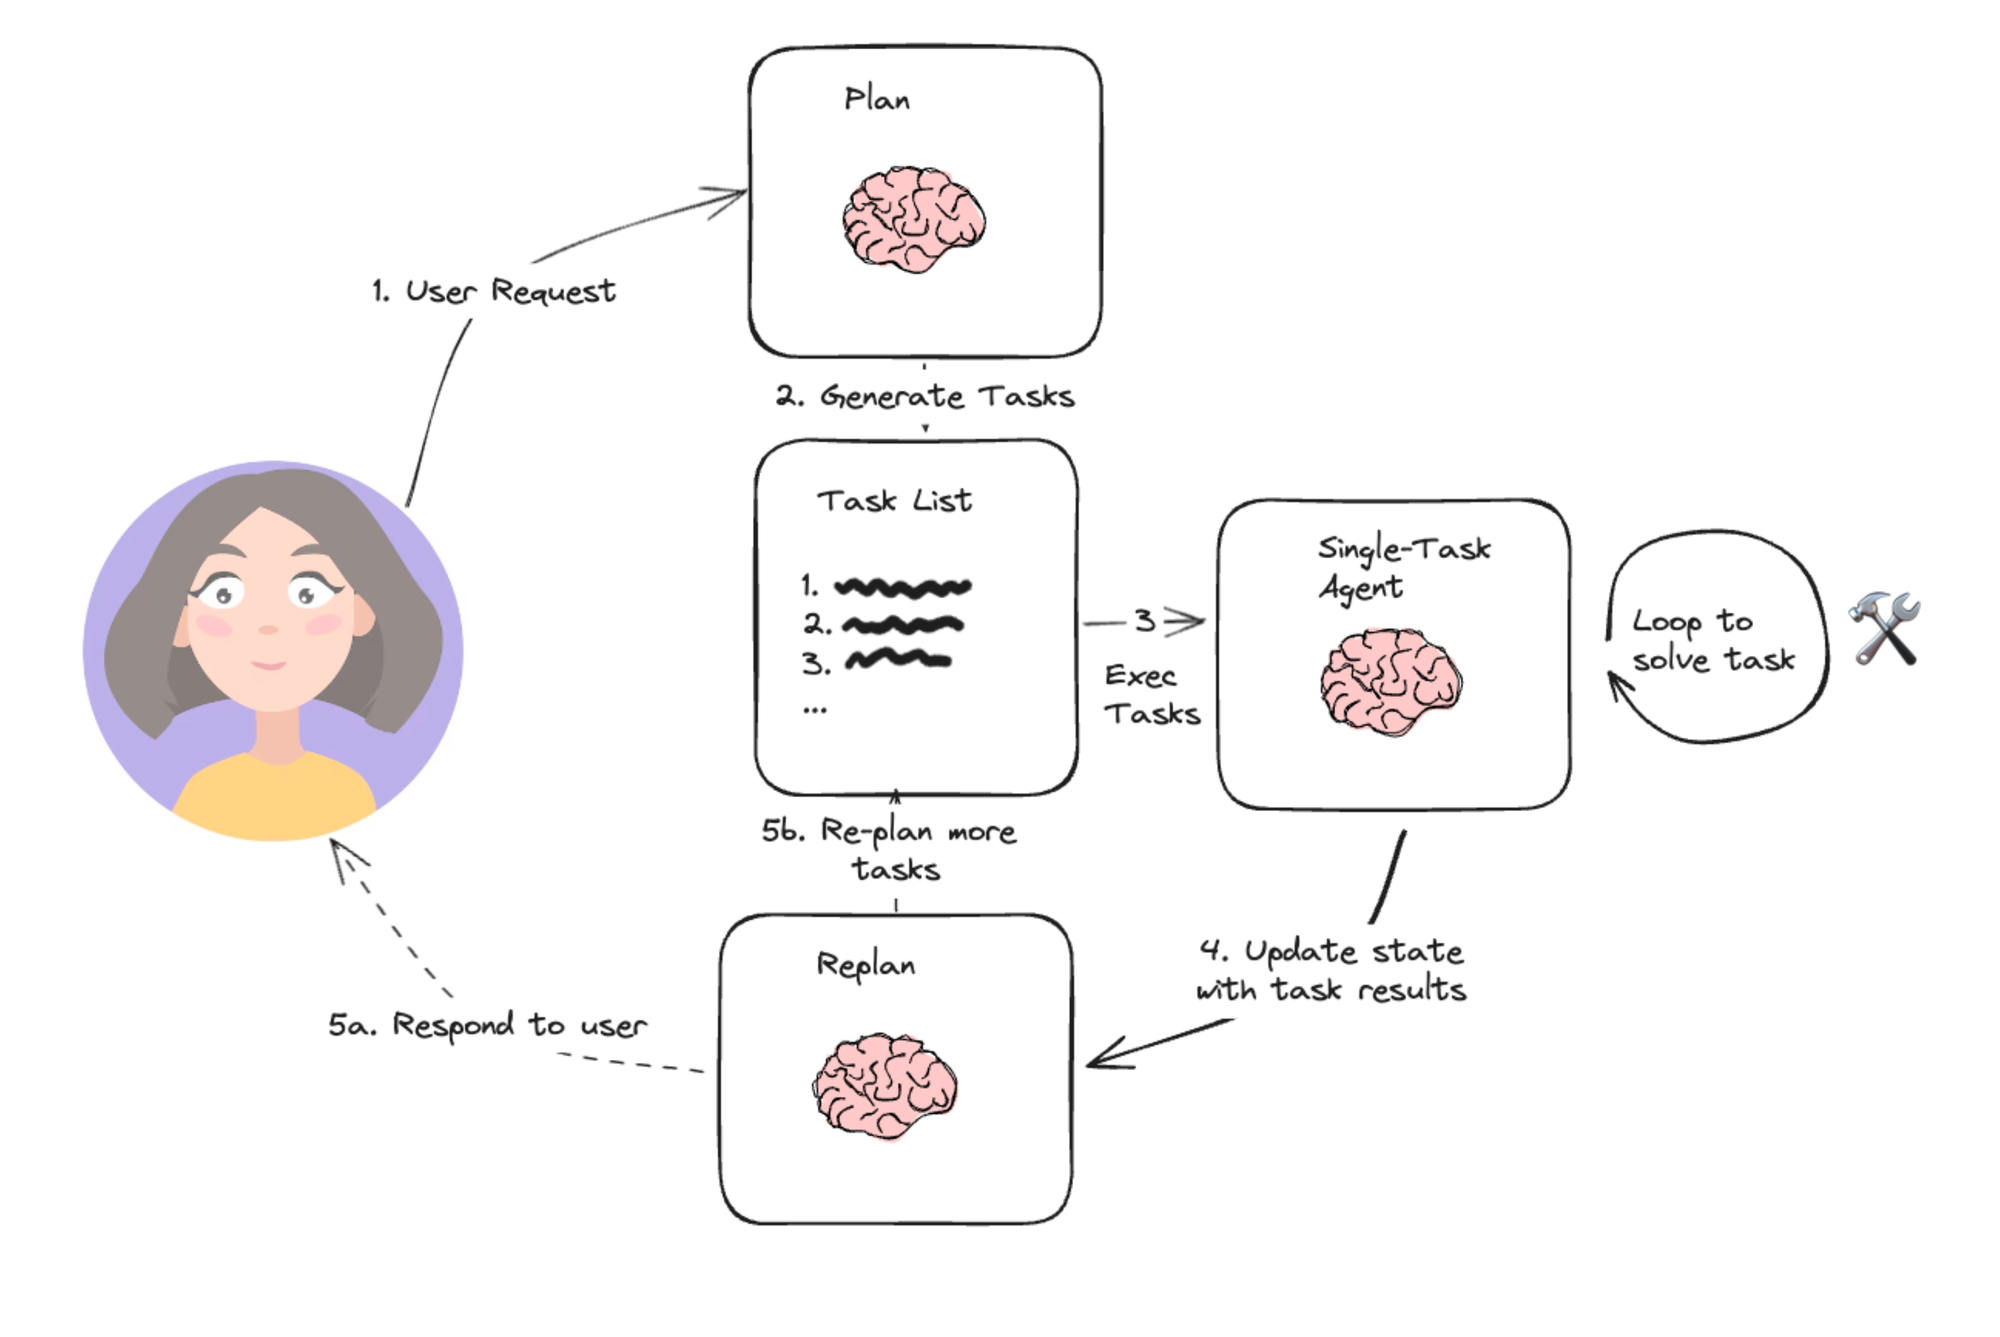


# Integración Técnica Empresarial: Function Calling con Esquemas JSON y Validación Estricta

## 1. Interoperabilidad Estocástica-Determinista y Function Calling

En la arquitectura de sistemas agénticos, el puente entre el espacio estocástico de los Modelos de Lenguaje de Gran Escala (LLM) y los sistemas de software deterministas (APIs corporativas, bases de datos transaccionales, microservicios) se establece mediante el mecanismo de **Function Calling** (o *Tool Use*).

Un LLM por sí mismo no ejecuta código ni realiza llamadas HTTP nativas; genera secuencias de tokens que representan la intención de invocar una función externa con un conjunto de argumentos específicos. Para que este proceso sea confiable en entornos de producción, el motor de inferencia debe ser acoplado a un **JSON Schema** formal que defina inequívocamente:

- Los nombres de los parámetros requeridos y opcionales.
- Los tipos de datos estrictos (ej. `string`, `integer`, `boolean`, `number`).
- Las restricciones semánticas y de formato (ej. patrones de expresiones regulares, rangos numéricos mediante `gt`, `lt`, etc.).

## 2. Validación Estricta de Esquemas y Mitigación de Desviaciones (*Schema Drift*)

La ausencia de validación previa en los argumentos devueltos por un LLM introduce vulnerabilidades severas, tales como la inyección de tipos de datos incorrectos, la omisión de campos obligatorios o la generación de parámetros alucinados que provocan fallos de ejecución en cascada (*Cascading Failures*) en las APIs externas.

La integración de **Pydantic v2** actúa como una capa de serialización y validación estricta en tiempo de ejecución. Al compilar los esquemas Pydantic en representaciones JSON Schema compatibles con el protocolo de llamadas a herramientas del proveedor del LLM, se garantiza que:

1. El modelo reciba metadatos precisos sobre la firma de la función.
2. Cualquier argumento emitido por el modelo sea validado algorítmicamente antes de invocar la función de negocio subyacente.
3. Se rechacen de forma determinista los payloads malformados mediante excepciones controladas de validación (`ValidationError`).


In [9]:
# =============================================================================
# Function Calling con Esquemas JSON y Validación Estricta en Pydantic v2

# =============================================================================

# Importamos el módulo os para la gestión de variables de entorno del sistema operativo
import os

# Importamos módulo nativo json para la serialización y deserialización de payloads
import json

# Importamos el gestor de secretos de Google Colab para recuperar credenciales de forma segura
from google.colab import userdata

# Importamos el tipo Type de typing para metaclases permitidas en definiciones de herramientas
from typing import Type

# Importamos BaseModel y Field de Pydantic v2 para el diseño de esquemas y validación estricta
from pydantic import BaseModel, Field, EmailStr

# Importamos la clase base para la construcción de herramientas personalizadas en LangChain
from langchain_core.tools import BaseTool

# Importamos abstracciones de mensajes para la estructuración del historial conversacional
from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage

# Importamos el conector oficial de LangChain para modelos generativos de Google Gemini
from langchain_google_genai import ChatGoogleGenerativeAI


# -----------------------------------------------------------------------------
# 0. Configuración de Credenciales del Entorno
# -----------------------------------------------------------------------------

def configurar_credenciales() -> bool:
    """
    Intenta recuperar la API Key de Google desde los secretos de Colab (userdata)
    y configurarla como variable de entorno global para los SDKs subyacentes.
    """
    try:
        # Extrae el secreto 'GOOGLE_API_KEY' y lo asigna al entorno del proceso
        os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')
        print(" Credenciales de Google API configuradas exitosamente.")
        return True
    except Exception as error:
        # Captura excepciones en caso de ausencia del secreto o fallo de ejecución en Colab
        print(f"X Error al cargar credenciales: {error}")
        return False


# -----------------------------------------------------------------------------
# 1. Definición de Esquemas JSON Schema Avanzados con Pydantic v2
# -----------------------------------------------------------------------------

class ProcesarTransaccionInput(BaseModel):
    """
    Esquema de validación estricta para una herramienta transaccional empresarial.
    Define restricciones algorítmicas avanzadas (patrones, rangos y tipos nativos).
    """
    # Identificador alfanumérico estricto validado mediante expresión regular
    id_transaccion: str = Field(
        ...,
        pattern=r"^TXN-\d{6}$",
        description="Identificador único de la transacción. Debe seguir estrictamente el formato 'TXN-######'."
    )
    # Monto monetario con validación estricta de rango numérico positivo
    monto: float = Field(
        ...,
        gt=0.0,
        description="Monto monetario de la transacción. Debe ser estrictamente mayor a 0.0."
    )
    # Moneda normalizada mediante acrónimo ISO
    moneda: str = Field(
        default="USD",
        description="Código ISO 4217 de la moneda (ej. USD, EUR, CLP)."
    )
    # Indicador booleano para procesamiento prioritario
    es_urgente: bool = Field(
        ...,
        description="Bandera booleana que define si la transacción requiere enrutamiento prioritario."
    )


# -----------------------------------------------------------------------------
# 2. Implementación de la Herramienta con Validación de Esquema
# -----------------------------------------------------------------------------

class ProcesarTransaccionTool(BaseTool):
    """
    Herramienta de escritura (Side-effecting) acoplada a un esquema Pydantic v2
    para garantizar la integridad tipada antes de la transmisión a la API externa.
    """
    # Nombre único identificador de la herramienta para el protocolo de Function Calling
    name: str = "procesar_transaccion_financiera"
    # Descripción técnica detallada para maximizar la precisión semántica del LLM
    description: str = (
        "Ejecuta una transacción financiera corporativa validando esquemas estrictos. "
        "Requiere ID con formato TXN-######, monto positivo y flag de urgencia."
    )
    # Vinculación formal del esquema Pydantic para la generación automática del JSON Schema
    args_schema: Type[BaseModel] = ProcesarTransaccionInput

    def _run(self, id_transaccion: str, monto: float, moneda: str, es_urgente: bool) -> str:
        """
        Ejecución síncrona de la lógica de negocio tras superar la validación estricta.
        """
        # Estructuración del payload de respuesta simulando la integración con una API externa
        respuesta_api = {
            "status": "AUTORIZADO",
            "gateway_id": "GW-998231",
            "transaccion": id_transaccion,
            "monto_procesado": f"{monto} {moneda}",
            "prioridad": "ALTA" if es_urgente else "ESTÁNDAR"
        }
        # Retorno del resultado serializado en formato JSON estándar
        return json.dumps(respuesta_api)


# -----------------------------------------------------------------------------
# 3. Flujo de Orquestación y Function Calling con Gemini
# -----------------------------------------------------------------------------

if __name__ == "__main__":
    # Verificamos e inicializamos las credenciales de Google requeridas
    if configurar_credenciales():
        # Inicialización del modelo de lenguaje configurado con temperatura estricta (0.0)
        llm = ChatGoogleGenerativeAI(
            model="gemini-3.5-flash-lite"
        )

        # Instanciación de la herramienta financiera desarrollada
        herramienta_transaccion = ProcesarTransaccionTool()
        lista_herramientas = [herramienta_transaccion]

        # Diccionario de indexación para la resolución determinista de llamadas del LLM
        mapa_herramientas = {tool.name: tool for tool in lista_herramientas}

        # Acoplamiento de herramientas al modelo mediante Function Calling y exportación de JSON Schema
        llm_con_herramientas = llm.bind_tools(lista_herramientas)

        # Definición de directrices de comportamiento para el agente mediante System Prompt
        prompt_sistema = SystemMessage(
            content=(
                "Eres un agente financiero automatizado. "
                "Tu objetivo es procesar solicitudes de transacciones utilizando exclusivamente "
                "la herramienta 'procesar_transaccion_financiera'. "
                "Asegúrate de extraer correctamente los parámetros del usuario adaptándolos "
                "a los requisitos estrictos de esquema (formato TXN-###### para el ID)."
            )
        )

        # Mensaje de entrada del usuario con datos que requieren mapeo tipado
        mensaje_usuario = HumanMessage(
            content="Por favor procesa una transacción urgente por un monto de 1500.50 dólares bajo el identificador TXN-448210."
        )

        # Inicialización del vector de historial conversacional (estado mutable del sistema)
        historial_mensajes = [prompt_sistema, mensaje_usuario]

        print("--- INICIANDO INVOCACIÓN CON FUNCTION CALLING ESTRICTO ---")

        # Invocación sincrónica al modelo pasando el contexto acumulado
        respuesta_llm = llm_con_herramientas.invoke(historial_mensajes)
        historial_mensajes.append(respuesta_llm)

        # Verificación condicional de emisión de llamadas a herramientas estructuradas
        if respuesta_llm.tool_calls:
            for tool_call in respuesta_llm.tool_calls:
                nombre_tool = tool_call["name"]
                args_tool = tool_call["args"]
                call_id = tool_call["id"]

                print(f"-> Intención de Function Calling detectada: '{nombre_tool}'")
                print(f"-> Argumentos extraídos por el LLM: {args_tool}")

                # Recuperación de la herramienta desde el mapa indexado
                herramienta_obj = mapa_herramientas[nombre_tool]

                # Ejecución de la herramienta invocando la validación estricta nativa de Pydantic v2
                resultado_ejecucion = herramienta_obj.invoke(args_tool)

                print(f"<- Respuesta del Servidor / API Externa: {resultado_ejecucion}")

                # Empaquetamiento de la observación en un ToolMessage para el cierre del flujo
                mensaje_observacion = ToolMessage(
                    content=resultado_ejecucion,
                    tool_call_id=call_id
                )
                historial_mensajes.append(mensaje_observacion)

            # Segunda invocación para sintetizar la respuesta final al usuario basada en el resultado
            respuesta_final = llm_con_herramientas.invoke(historial_mensajes)
            print(f"\n[RESPUESTA FINAL DEL AGENTE]:\n{respuesta_final.content}")
        else:
            print("\n[EL MODELO NO EMITIó LLAMADAS A HERRAMIENTAS]:")
            print(respuesta_llm.content)
    else:
        print("No se pudo inicializar el flujo debido a un fallo crítico en las credenciales.")

 Credenciales de Google API configuradas exitosamente.
--- INICIANDO INVOCACIÓN CON FUNCTION CALLING ESTRICTO ---
-> Intención de Function Calling detectada: 'procesar_transaccion_financiera'
-> Argumentos extraídos por el LLM: {'moneda': 'USD', 'monto': 1500.5, 'es_urgente': True, 'id_transaccion': 'TXN-448210'}
<- Respuesta del Servidor / API Externa: {"status": "AUTORIZADO", "gateway_id": "GW-998231", "transaccion": "TXN-448210", "monto_procesado": "1500.5 USD", "prioridad": "ALTA"}

[RESPUESTA FINAL DEL AGENTE]:
[{'type': 'text', 'text': 'La transacción **TXN-448210** por un monto de **1500.5 USD** ha sido procesada exitosamente bajo enrutamiento prioritario. \n\n* **Estado:** AUTORIZADO\n* **ID de Pasarela:** GW-998231\n* **Prioridad:** ALTA', 'extras': {'signature': 'EmAKXgFpFH0TtLYcLH996148dNkauN61bOGR3yEZ5DSeKX+othh8zd8ZaWfU0Haelx44aaX2BdlUmAvQhcpNb/2GlYgnPn6jPkUu6hdDopouYFpsThL8SLWFXF2hW+hgNzs='}}]



# Protocolo MCP (Model Context Protocol) e Integración de Herramientas de Consulta y Escritura



### 1. El Problema del Acoplamiento Estrecho en Sistemas Agénticos

En las arquitecturas tradicionales de agentes monolíticos, las herramientas de recuperación de datos (consulta) y las herramientas transaccionales (escritura) se encuentran fuertemente acopladas (*tight coupling*) dentro del mismo proceso de ejecución del Modelo de Lenguaje. Esto genera problemas críticos de mantenimiento, vulnerabilidades de seguridad al exponer credenciales directamente en el espacio del agente y una alta fricción al escalar o modificar las fuentes de datos externas.

### 2. Model Context Protocol (MCP): Arquitectura Cliente-Servidor

Propuesto como un estándar abierto para estandarizar la provisión de contexto y herramientas a los LLMs, el **Model Context Protocol (MCP)** separa la arquitectura en dos componentes desacoplados:

- **MCP Client (Host del Agente):** El sistema orquestador (como LangChain, LangGraph o una aplicación cliente) que gestiona el ciclo de razonamiento del LLM, el historial de estados y las políticas de seguridad.

- **MCP Server (Servidor de Contexto/Herramientas):** Un microservicio o proceso aislado que expone capacidades normalizadas divididas en tres categorías:
  1. *Recursos (Resources):* Datos estáticos o dinámicos que se pueden leer (ej. archivos, bases de datos, logs).
  2. *Prompts (Prompts):* Plantillas de comportamiento estandarizadas gestionadas externamente.
  3. *Herramientas (Tools):* Funciones ejecutables con esquemas de validación estrictos que permiten modificar el entorno (*side-effecting*).

Mediante esta abstracción, el agente agéntico deja de conocer la infraestructura física de las bases de datos o APIs, interactuando exclusivamente a través de contratos de interfaz estandarizados por el protocolo MCP.


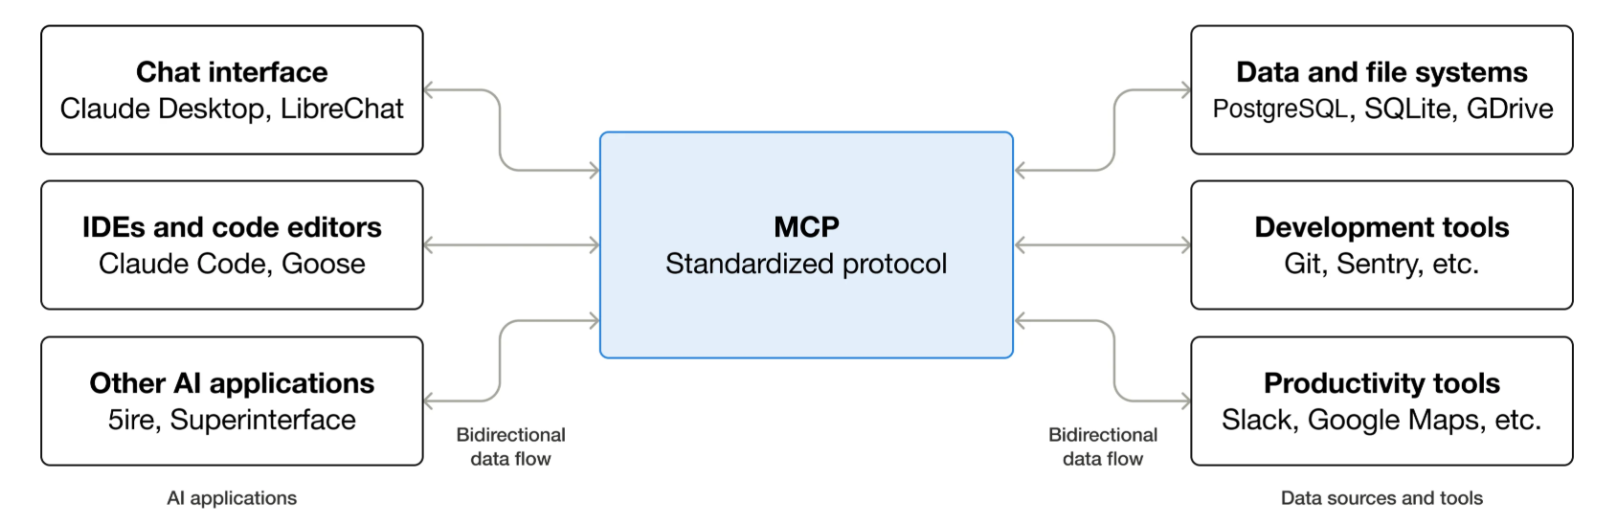

In [11]:
# =============================================================================
# Model Context Protocol (MCP) y Desacoplamiento de Herramientas

# =============================================================================

# Importamos el módulo os para la gestión de variables de entorno del sistema operativo
import os

# Importamos módulo nativo json para la serialización de payloads entre capas
import json

# Importamos el gestor de secretos de Google Colab para recuperar credenciales de forma segura
from google.colab import userdata

# Importamos metaclase Type de typing para tipados especiales permitidos en herramientas
from typing import Type

# Importamos BaseModel y Field de Pydantic v2 para esquemas de validación estricta
from pydantic import BaseModel, Field

# Importamos la clase base para la construcción de herramientas personalizadas en LangChain
from langchain_core.tools import BaseTool

# Importamos abstracciones de mensajes para la estructuración del historial conversacional
from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage

# Importamos el conector oficial de LangChain para modelos generativos de Google Gemini
from langchain_google_genai import ChatGoogleGenerativeAI


# -----------------------------------------------------------------------------
# 0. Configuración de Credenciales del Entorno
# -----------------------------------------------------------------------------

def configurar_credenciales() -> bool:
    """
    Intenta recuperar la API Key de Google desde los secretos de Colab (userdata)
    y configurarla como variable de entorno global para los SDKs subyacentes.
    """
    try:
        # Extrae el secreto 'GOOGLE_API_KEY' y lo asigna al entorno del proceso
        os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')
        print(" Credenciales de Google API configuradas exitosamente.")
        return True
    except Exception as error:
        # Captura excepciones en caso de ausencia del secreto o fallo de ejecución en Colab
        print(f"X Error al cargar credenciales: {error}")
        return False


# -----------------------------------------------------------------------------
# 1. Simulación de la Capa de Servidor MCP (Model Context Protocol Server)
# -----------------------------------------------------------------------------

class MCPServerSimulado:
    """
    Simula un servidor MCP aislado que desacopla la lógica de persistencia
    y ejecución de herramientas del agente cliente principal.
    """
    def __init__(self) -> None:
        # Base de datos simulada interna del servidor MCP (aislada del LLM)
        self.almacenamiento_interno = {
            "USR-001": {"nombre": "Ana Pérez", "saldo": 1200.50, "estado": "ACTIVO"},
            "USR-002": {"nombre": "Carlos Gómez", "saldo": 450.00, "estado": "SUSPENDIDO"}
        }

    def mcp_leer_recurso(self, id_usuario: str) -> str:
        """
        Expone un recurso de solo lectura (Read-only) a través del protocolo MCP.
        """
        if id_usuario in self.almacenamiento_interno:
            return json.dumps({"status": "OK", "data": self.almacenamiento_interno[id_usuario]})
        return json.dumps({"status": "ERROR", "mensaje": f"Usuario '{id_usuario}' no encontrado en el servidor MCP."})

    def mcp_escribir_mutacion(self, id_usuario: str, monto_ajuste: float) -> str:
        """
        Expone una herramienta de escritura (Side-effecting) validada a través del protocolo MCP.
        """
        if id_usuario not in self.almacenamiento_interno:
            return json.dumps({"status": "ERROR", "mensaje": "Usuario no válido para transacción."})

        # Mutación controlada del estado interno en el servidor MCP
        self.almacenamiento_interno[id_usuario]["saldo"] += monto_ajuste
        nuevo_saldo = self.almacenamiento_interno[id_usuario]["saldo"]

        return json.dumps({
            "status": "MUTACION_EXITOSA",
            "servidor_mcp": "mcp-core-cluster-01",
            "usuario": id_usuario,
            "nuevo_saldo": nuevo_saldo
        })


# Instanciación global del servidor MCP que será consumido por el cliente agéntico
servidor_mcp_global = MCPServerSimulado()


# -----------------------------------------------------------------------------
# 2. Definición de Esquemas Pydantic v2 para el Cliente MCP
# -----------------------------------------------------------------------------

class ConsultarUsuarioMCPInput(BaseModel):
    """
    Esquema de validación para la herramienta cliente MCP de consulta.
    """
    id_usuario: str = Field(..., description="Identificador único del usuario (formato USR-###).")


class AjustarSaldoMCPInput(BaseModel):
    """
    Esquema de validación para la herramienta cliente MCP de escritura/mutación.
    """
    id_usuario: str = Field(..., description="Identificador único del usuario (formato USR-###).")
    monto_ajuste: float = Field(..., description="Monto monetario a sumar o restar del saldo del usuario.")


# -----------------------------------------------------------------------------
# 3. Definición de Herramientas Acopladas al Protocolo MCP en LangChain
# -----------------------------------------------------------------------------

class MCPToolConsultarUsuario(BaseTool):
    """
    Herramienta cliente que delega la recuperación de datos al servidor MCP.
    """
    name: str = "mcp_consultar_usuario"
    description: str = "Consulta la información de un usuario en el servidor MCP remoto (Read-only)."
    args_schema: Type[BaseModel] = ConsultarUsuarioMCPInput

    def _run(self, id_usuario: str) -> str:
        # Delegación transparente de la llamada al servidor MCP simulado
        return servidor_mcp_global.mcp_leer_recurso(id_usuario)


class MCPToolAjustarSaldo(BaseTool):
    """
    Herramienta cliente que delega la mutación de datos al servidor MCP.
    """
    name: str = "mcp_ajustar_saldo"
    description: str = "Modifica el saldo de un usuario a través del servidor MCP (Side-effecting write)."
    args_schema: Type[BaseModel] = AjustarSaldoMCPInput

    def _run(self, id_usuario: str, monto_ajuste: float) -> str:
        # Delegación transparente de la mutación al servidor MCP simulado
        return servidor_mcp_global.mcp_escribir_mutacion(id_usuario, monto_ajuste)


# -----------------------------------------------------------------------------
# 4. Flujo de Orquestación Cliente-Servidor MCP con Gemini
# -----------------------------------------------------------------------------

if __name__ == "__main__":
    # Verificamos e inicializamos las credenciales de Google requeridas
    if configurar_credenciales():
        # Inicialización del modelo Gemini configurado con temperatura estricta (0.0)
        llm = ChatGoogleGenerativeAI(
            model="gemini-3.5-flash-lite"
        )

        # Instanciación de las herramientas clientes conectadas a la arquitectura MCP
        herramienta_consulta_mcp = MCPToolConsultarUsuario()
        herramienta_escritura_mcp = MCPToolAjustarSaldo()
        lista_herramientas_mcp = [herramienta_consulta_mcp, herramienta_escritura_mcp]

        # Mapeo determinista para resolver las llamadas emitidas por el LLM
        mapa_herramientas_mcp = {tool.name: tool for tool in lista_herramientas_mcp}

        # Acoplamiento de herramientas al modelo mediante Function Calling nativo
        llm_con_mcp = llm.bind_tools(lista_herramientas_mcp)

        # Prompt de sistema estableciendo el rol del agente bajo arquitectura MCP
        prompt_sistema = SystemMessage(
            content=(
                "Eres un agente inteligente conectado a una arquitectura Model Context Protocol (MCP). "
                "Utiliza las herramientas 'mcp_consultar_usuario' y 'mcp_ajustar_saldo' para resolver "
                "las peticiones del usuario de manera desacoplada y segura."
            )
        )

        # Mensaje de entrada del usuario solicitando una consulta y una mutación de estado
        mensaje_usuario = HumanMessage(
            content="Por favor revisa el estado del usuario USR-001 y luego asígnale un ajuste positivo de 250.00 en su saldo."
        )

        # Inicialización del vector de historial conversacional
        historial_mensajes = [prompt_sistema, mensaje_usuario]

        print("--- INICIANDO FLUJO DE ORQUESTACIÓN BAJO ARQUITECTURA MCP ---")

        # Control de iteraciones del bucle agéntico
        activo = True
        paso = 1

        while activo and paso <= 4:
            print(f"\n--- CICLO MCP PASO {paso} ---")

            # Invocación sincrónica al modelo Gemini
            respuesta_llm = llm_con_mcp.invoke(historial_mensajes)
            historial_mensajes.append(respuesta_llm)

            # Verificación de solicitudes de Function Calling hacia el servidor MCP
            if respuesta_llm.tool_calls:
                for tool_call in respuesta_llm.tool_calls:
                    nombre_tool = tool_call["name"]
                    args_tool = tool_call["args"]
                    call_id = tool_call["id"]

                    print(f"-> Solicitud MCP enviada al Servidor: '{nombre_tool}' con args: {args_tool}")

                    # Recuperación de la herramienta cliente y ejecución delegada
                    herramienta_obj = mapa_herramientas_mcp[nombre_tool]
                    resultado_mcp = herramienta_obj.invoke(args_tool)

                    print(f"<- Respuesta recibida desde el Servidor MCP: {resultado_mcp}")

                    # Inyección de la observación en el historial de mensajes
                    mensaje_observacion = ToolMessage(
                        content=resultado_mcp,
                        tool_call_id=call_id
                    )
                    historial_mensajes.append(mensaje_observacion)
            else:
                print(f"\n[RESPUESTA FINAL DEL AGENTE MCP]:\n{respuesta_llm.content}")
                activo = False

            paso += 1
    else:
        print("Fallo crítico en la inicialización de credenciales MCP.")

 Credenciales de Google API configuradas exitosamente.
--- INICIANDO FLUJO DE ORQUESTACIÓN BAJO ARQUITECTURA MCP ---

--- CICLO MCP PASO 1 ---
-> Solicitud MCP enviada al Servidor: 'mcp_consultar_usuario' con args: {'id_usuario': 'USR-001'}
<- Respuesta recibida desde el Servidor MCP: {"status": "OK", "data": {"nombre": "Ana P\u00e9rez", "saldo": 1200.5, "estado": "ACTIVO"}}

--- CICLO MCP PASO 2 ---
-> Solicitud MCP enviada al Servidor: 'mcp_ajustar_saldo' con args: {'monto_ajuste': 250, 'id_usuario': 'USR-001'}
<- Respuesta recibida desde el Servidor MCP: {"status": "MUTACION_EXITOSA", "servidor_mcp": "mcp-core-cluster-01", "usuario": "USR-001", "nuevo_saldo": 1450.5}

--- CICLO MCP PASO 3 ---

[RESPUESTA FINAL DEL AGENTE MCP]:
[{'type': 'text', 'text': 'He revisado con éxito el estado del usuario y aplicado el ajuste solicitado.\n\n**Detalles de la operación:**\n* **Usuario:** USR-001 (Ana Pérez)\n* **Estado inicial:** ACTIVO\n* **Saldo anterior:** 1200.50\n* **Ajuste aplicado:** +2


# Control de Seguridad, Transacciones y Modificación Segura de Datos en Entornos Empresariales

## 1. Modelos de Control de Acceso y Principio de Privilegio Mínimo en Agentes

En las arquitecturas de sistemas agénticos orientados a producción, la ejecución de operaciones de escritura o mutación de estado (*side-effecting write tools*) introduce riesgos operativos críticos, tales como la corrupción de datos persistentes, la ejecución de transacciones financieras no autorizadas o la brecha de normativas de cumplimiento corporativo (*compliance*).

Para mitigar estos vectores de riesgo, la ingeniería de software de IA implementa políticas estrictas de **Control de Acceso Basado en Roles (RBAC)** y el **Principio de Privilegio Mínimo**. Esto implica que un agente autónomo o un sub-agente especializado no posee permisos universales sobre el entorno; cada herramienta de escritura debe validar criptográficamente o mediante metadatos de sesión el rol del emisor y los límites operacionales autorizados antes de conceder la mutación de estado.

## 2. Transaccionalidad, Claves de Idempotencia y Robustez Operacional

Las herramientas con efectos secundarios (*side-effecting*) requieren garantías formales de transaccionalidad inspiradas en los principios ACID (Atomicidad, Consistencia, Aislamiento y Durabilidad). Dado que los sistemas de agentes operan bajo ciclos estocásticos propensos a reintentos automáticos (*retries*), la integración de **Claves de Idempotencia (*Idempotency Keys*)** es obligatoria para prevenir ejecuciones duplicadas ante fallos transitorios de red o *timeouts* del modelo de lenguaje.

Asimismo, siguiendo los principios de diseño de arquitectura de sistemas agénticos robustos, se deben implementar salvaguardas de manejo de excepciones y validación de precondiciones de seguridad de forma previa a cualquier operación de escritura:

> "Implementar reintentos, manejo de excepciones y mensajes de error claros."


In [13]:
# =============================================================================
# MÓDULO 5: Control de Seguridad, Transacciones y Modificación Segura de Datos

# =============================================================================

# Importamos el módulo os para la gestión de variables de entorno del sistema operativo
import os

# Importamos módulo nativo json para la serialización estructurada de payloads transaccionales
import json

# Importamos módulo uuid para generar identificadores unívocos de idempotencia
import uuid

# Importamos el gestor de secretos de Google Colab para recuperar credenciales de forma segura
from google.colab import userdata

# Importamos la metaclase Type de typing para tipados especiales permitidos en herramientas
from typing import Type

# Importamos BaseModel y Field de Pydantic v2 para esquemas de validación estricta y control RBAC
from pydantic import BaseModel, Field

# Importamos la clase base para la construcción de herramientas personalizadas en LangChain
from langchain_core.tools import BaseTool

# Importamos abstracciones de mensajes para la estructuración del historial conversacional
from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage

# Importamos el conector oficial de LangChain para modelos generativos de Google Gemini
from langchain_google_genai import ChatGoogleGenerativeAI


# -----------------------------------------------------------------------------
# 0. Configuración de Credenciales del Entorno
# -----------------------------------------------------------------------------

def configurar_credenciales() -> bool:
    """
    Intenta recuperar la API Key de Google desde los secretos de Colab (userdata)
    y configurarla como variable de entorno global para los SDKs subyacentes.
    """
    try:
        # Extrae el secreto 'GOOGLE_API_KEY' y lo asigna al entorno del proceso operativo
        os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')
        print(" Credenciales de Google API configuradas exitosamente.")
        return True
    except Exception as error:
        # Captura excepciones en caso de ausencia del secreto o fallo de ejecución en Colab
        print(f"X Error al cargar credenciales: {error}")
        return False


# -----------------------------------------------------------------------------
# 1. Capa de Servidor Transaccional con Salvaguardas de Seguridad y RBAC
# -----------------------------------------------------------------------------

class ServidorTransaccionalSeguro:
    """
    Simula un subsistema empresarial con control de acceso (RBAC),
    verificación de precondiciones y control de idempotencia para escrituras seguras.
    """
    def __init__(self) -> None:
        # Base de datos interna protegida con saldos y perfiles de seguridad
        self.cuentas_corporativas = {
            "ACC-9001": {"titular": "Finanzas Globales", "saldo": 50000.0, "nivel_acceso_requerido": "ADMIN"}
        }
        # Caché de idempotencia para evitar la duplicación de transacciones reintentadas
        self.registro_idempotencia = set()

    def ejecutar_escritura_segura(self, token_rol: str, cuenta_destino: str, monto: float, clave_idempotencia: str) -> str:
        """
        Ejecuta una mutación de estado aplicando salvaguardas de seguridad empresariales.
        """
        # Salvaguarda 1: Control de Acceso Basado en Roles (RBAC)
        if token_rol != "ADMIN":
            return json.dumps({
                "status": "ERROR_SEGURIDAD_ACCESO_DENEGADO",
                "mensaje": f"El rol '{token_rol}' no cuenta con privilegios para ejecutar operaciones de escritura."
            })

        # Salvaguarda 2: Verificación de existencia de la entidad de destino
        if cuenta_destino not in self.cuentas_corporativas:
            return json.dumps({
                "status": "ERROR_PRECONDICION",
                "mensaje": f"La cuenta destino '{cuenta_destino}' no existe en el registro central."
            })

        # Salvaguarda 3: Validación de Idempotencia para prevenir doble gasto o mutación repetida
        if clave_idempotencia in self.registro_idempotencia:
            return json.dumps({
                "status": "ERROR_IDEMPOTENCIA",
                "mensaje": f"La clave de idempotencia '{clave_idempotencia}' ya fue procesada anteriormente. Operación rechazada."
            })

        try:
            # Salvaguarda 4: Validación de precondición de negocio (montos positivos y límites)
            if monto <= 0.0 or monto > 10000.0:
                raise ValueError("El monto excede el límite de transferencia autorizado por evento o es inválido.")

            # Mutación controlada del estado persistente
            self.cuentas_corporativas[cuenta_destino]["saldo"] += monto

            # Registro de la clave en la caché de idempotencia tras el éxito atómico
            self.registro_idempotencia.add(clave_idempotencia)

            return json.dumps({
                "status": "TRANSACCION_AUTORIZADA_Y_REGISTRADA",
                "idempotencia_key": clave_idempotencia,
                "cuenta": cuenta_destino,
                "nuevo_saldo": self.cuentas_corporativas[cuenta_destino]["saldo"]
            })

        except Exception as ex:
            # Manejo robusto de excepciones con mensajes claros orientados a auditoría[cite: 1]
            return json.dumps({
                "status": "ERROR_TRANSACCIONAL_CRITICO",
                "detalle_excepcion": str(ex)
            })


# Instanciación global del subsistema transaccional seguro
servidor_seguro_global = ServidorTransaccionalSeguro()


# -----------------------------------------------------------------------------
# 2. Definición del Esquema Pydantic v2 para la Herramienta de Escritura Segura
# -----------------------------------------------------------------------------

class AuditoriaEscrituraInput(BaseModel):
    """
    Esquema de validación estricta para garantizar que el modelo provea
    los metadatos de seguridad obligatorios antes de invocar la herramienta de escritura.
    """
    token_rol: str = Field(..., description="Rol de seguridad provisto por el agente (ej. 'ADMIN', 'GUEST').")
    cuenta_destino: str = Field(..., description="Código de cuenta corporativa de destino (formato ACC-####).")
    monto: float = Field(..., gt=0.0, description="Monto monetario de la transferencia autorizada.")
    clave_idempotencia: str = Field(..., description="UUID único generado para garantizar idempotencia transaccional.")


# -----------------------------------------------------------------------------
# 3. Definición de la Herramienta de Escritura Segura en LangChain
# -----------------------------------------------------------------------------

class HerramientaEscrituraSegura(BaseTool):
    """
    Herramienta de escritura (Side-effecting) blindada con controles de acceso
    y validación transaccional estricta.
    """
    name: str = "ejecutar_transferencia_segura"
    description: str = (
        "Ejecuta una transferencia financiera de escritura aplicando controles RBAC, "
        "validación de límites y protección por clave de idempotencia."
    )
    args_schema: Type[BaseModel] = AuditoriaEscrituraInput

    def _run(self, token_rol: str, cuenta_destino: str, monto: float, clave_idempotencia: str) -> str:
        # Delegación segura de la operación al servidor transaccional con salvaguardas
        return servidor_seguro_global.ejecutar_escritura_segura(
            token_rol=token_rol,
            cuenta_destino=cuenta_destino,
            monto=monto,
            clave_idempotencia=clave_idempotencia
        )


# -----------------------------------------------------------------------------
# 4. Flujo de Orquestación y Verificación de Salvaguardas con Gemini
# -----------------------------------------------------------------------------

if __name__ == "__main__":
    # Verificamos e inicializamos las credenciales de Google requeridas
    if configurar_credenciales():
        # Inicialización del modelo de lenguaje configurado con temperatura estricta (0.0)
        llm = ChatGoogleGenerativeAI(
            model="gemini-3.5-flash-lite"
        )

        # Instanciación de la herramienta de escritura segura
        herramienta_segura = HerramientaEscrituraSegura()
        lista_herramientas = [herramienta_segura]

        # Mapeo determinista para resolver las llamadas emitidas por el LLM
        mapa_herramientas = {tool.name: tool for tool in lista_herramientas}

        # Acoplamiento de herramientas al modelo mediante Function Calling nativo
        llm_con_seguridad = llm.bind_tools(lista_herramientas)

        # Prompt de sistema imponiendo restricciones estrictas de seguridad corporativa
        prompt_sistema = SystemMessage(
            content=(
                "Eres un agente de operaciones financieras con restricciones estrictas de seguridad. "
                "Para ejecutar 'ejecutar_transferencia_segura', debes verificar obligatoriamente que cuentas "
                "con el rol 'ADMIN', que el monto esté dentro de los límites permitidos y debes generar "
                "un UUID v4 único como 'clave_idempotencia' para cada llamada."
            )
        )

        # Mensaje de entrada del usuario solicitando una transferencia corporativa
        # Generamos dinámicamente un UUID de idempotencia válido para la prueba
        uuid_prueba = str(uuid.uuid4())
        mensaje_usuario = HumanMessage(
            content=f"Transfiere 2500.00 dólares a la cuenta ACC-9001 utilizando mi rol de ADMIN y clave {uuid_prueba}."
        )

        # Inicialización del vector de historial conversacional
        historial_mensajes = [prompt_sistema, mensaje_usuario]

        print("--- INICIANDO FLUJO DE ESCRITURA SEGURA CON SALVAGUARDAS ---")

        # Control de ejecución del ciclo agéntico
        activo = True
        paso = 1

        while activo and paso <= 3:
            print(f"\n--- CICLO DE SEGURIDAD PASO {paso} ---")

            # Invocación sincrónica al modelo Gemini
            respuesta_llm = llm_con_seguridad.invoke(historial_mensajes)
            historial_mensajes.append(respuesta_llm)

            # Verificación de solicitudes de Function Calling hacia la herramienta blindada
            if respuesta_llm.tool_calls:
                for tool_call in respuesta_llm.tool_calls:
                    nombre_tool = tool_call["name"]
                    args_tool = tool_call["args"]
                    call_id = tool_call["id"]

                    print(f"-> Intención de escritura detectada: '{nombre_tool}'")
                    print(f"-> Metadatos de seguridad provistos: {args_tool}")

                    # Recuperación y ejecución de la herramienta validada por Pydantic v2
                    herramienta_obj = mapa_herramientas[nombre_tool]
                    resultado_ejecucion = herramienta_obj.invoke(args_tool)

                    print(f"<- Respuesta del Subsistema Transaccional: {resultado_ejecucion}")

                    # Inyección de la observación en el historial de mensajes
                    mensaje_observacion = ToolMessage(
                        content=resultado_ejecucion,
                        tool_call_id=call_id
                    )
                    historial_mensajes.append(mensaje_observacion)
            else:
                print(f"\n[RESPUESTA FINAL DEL AGENTE SEGURO]:\n{respuesta_llm.content}")
                activo = False

            paso += 1
    else:
        print("Fallo crítico en la inicialización de credenciales de seguridad.")

 Credenciales de Google API configuradas exitosamente.
--- INICIANDO FLUJO DE ESCRITURA SEGURA CON SALVAGUARDAS ---

--- CICLO DE SEGURIDAD PASO 1 ---
-> Intención de escritura detectada: 'ejecutar_transferencia_segura'
-> Metadatos de seguridad provistos: {'clave_idempotencia': 'd7923f3e-3ef6-4c4e-a25d-735227e916c6', 'cuenta_destino': 'ACC-9001', 'token_rol': 'ADMIN', 'monto': 2500}
<- Respuesta del Subsistema Transaccional: {"status": "TRANSACCION_AUTORIZADA_Y_REGISTRADA", "idempotencia_key": "d7923f3e-3ef6-4c4e-a25d-735227e916c6", "cuenta": "ACC-9001", "nuevo_saldo": 52500.0}

--- CICLO DE SEGURIDAD PASO 2 ---

[RESPUESTA FINAL DEL AGENTE SEGURO]:
[{'type': 'text', 'text': 'La transferencia de **2500.00 dólares** a la cuenta **ACC-9001** se ha ejecutado exitosamente utilizando el rol `ADMIN`. \n\n* **Estado:** TRANSACCION_AUTORIZADA_Y_REGISTRADA\n* **Clave de Idempotencia:** d7923f3e-3ef6-4c4e-a25d-735227e916c6\n* **Nuevo Saldo (Cuenta Destino):** $52,500.00', 'extras': {'signature'


# Orquestación Secuencial Determinista (Pipeline Processing)



### 1. Modelos de Flujo Lineal y Tuberías de Datos en IA (*Pipeline Processing*)

En la ingeniería de sistemas multi-agente, la **orquestación secuencial determinista** (también conocida como patrón *Pipeline* o tubería de datos) define una topología de comunicación unidireccional donde el espacio de trabajo opera de manera estrictamente lineal.

A diferencia de los grafos de control dinámicos o los modelos en estrella (*hub-and-spoke*), una tubería secuencial transfiere el estado acumulado y los artefactos generados de un agente \(A_i\) directamente como entrada inicial para el agente subsiguiente \(A_{i+1}\). Este enfoque elimina la ambigüedad en la toma de decisiones sobre a quién delegar, garantizando un flujo determinista donde cada etapa transforma un *payload* específico con una responsabilidad única y acotada.

### 2. Mecánica de Transferencia de Estado y Control de Errores en Pipelines

La robustez de una orquestación secuencial en entornos empresariales depende de dos factores arquitectónicos:

1. **Inmutabilidad o Versionado del Estado Intermedio:** Cada agente en la tubería procesa el *payload* recibido y añade su contribución sin destruir los metadatos de las etapas previas, permitiendo una trazabilidad completa del ciclo de transformación.

2. **Validación de Contratos de Interfaz (*Payload Validation*):** Dado que la salida de un agente se convierte en la entrada del siguiente, la alteración o corrupción no controlada del texto o JSON intermedio provoca fallos en cascada. Por ello, cada transición entre etapas requiere validación estricta mediante esquemas.


In [15]:
# =============================================================================
# MÓDULO 6: Orquestación Secuencial Determinista (Pipeline Processing)

# =============================================================================

# Importamos el módulo os para la gestión de variables de entorno del sistema operativo
import os

# Importamos módulo nativo json para la serialización de payloads entre etapas del pipeline
import json

# Importamos el gestor de secretos de Google Colab para recuperar credenciales de forma segura
from google.colab import userdata

# Importamos BaseModel y Field de Pydantic v2 para validar los contratos de datos entre etapas
from pydantic import BaseModel, Field

# Importamos abstracciones de mensajes para estructurar los prompts de las etapas
from langchain_core.messages import SystemMessage, HumanMessage

# Importamos el conector oficial de LangChain para modelos generativos de Google Gemini
from langchain_google_genai import ChatGoogleGenerativeAI


# -----------------------------------------------------------------------------
# 0. Configuración de Credenciales del Entorno
# -----------------------------------------------------------------------------

def configurar_credenciales() -> bool:
    """
    Intenta recuperar la API Key de Google desde los secretos de Colab (userdata)
    y configurarla como variable de entorno global para los SDKs subyacentes.
    """
    try:
        # Extrae el secreto 'GOOGLE_API_KEY' y lo asigna al entorno del proceso operativo
        os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')
        # Imprime mensaje de éxito si la asignación es correcta
        print(" Credenciales de Google API configuradas exitosamente.")
        # Retorna True indicando que el proceso de autenticación fue exitoso
        return True
    except Exception as error:
        # Captura excepciones en caso de ausencia del secreto o fallo de ejecución en Colab
        print(f"X Error al cargar credenciales: {error}")
        # Retorna False ante cualquier fallo de autenticación
        return False


# -----------------------------------------------------------------------------
# 1. Definición de Esquemas de Contrato para el Pipeline
# -----------------------------------------------------------------------------

class OutputEtapaExtractor(BaseModel):
    """Contrato de salida estricta para la Etapa 1 (Extracción de Entidades)."""
    # Campo para almacenar el nombre o identificador de la entidad extraída
    entidad_financiera: str = Field(..., description="Nombre o identificador de la entidad analizada.")
    # Campo numérico para el monto extraído del texto no estructurado
    monto_reportado: float = Field(..., description="Monto numérico extraído del texto bruto.")
    # Colección usando tipo nativo list[str] para los indicadores clave identificados
    indicadores_clave: list[str] = Field(..., description="Lista de palabras clave o métricas identificadas.")


class OutputEtapaAnalista(BaseModel):
    """Contrato de salida estricta para la Etapa 2 (Análisis de Riesgo)."""
    # Campo para el nivel de riesgo evaluado (BAJO, MEDIO, ALTO)
    nivel_riesgo: str = Field(..., description="Calificación de riesgo evaluada (BAJO, MEDIO, ALTO).")
    # Campo de texto detallando el porqué de la calificación de riesgo
    justificacion_tecnica: str = Field(..., description="Fundamentación técnica del nivel de riesgo asignado.")


# -----------------------------------------------------------------------------
# 2. Implementación de la Tubería Secuencial Determinista (Pipeline)
# -----------------------------------------------------------------------------

if __name__ == "__main__":
    # Verificamos e inicializamos las credenciales de Google requeridas antes de iniciar el pipeline
    if configurar_credenciales():
        # Inicialización del modelo Gemini configurado con temperatura estricta (0.0) para máxima predictibilidad
        llm = ChatGoogleGenerativeAI(
            model="gemini-3.5-flash-lite"
        )

        # Payload de entrada bruto simulando un informe financiero no estructurado
        informe_bruto = (
            "Durante el último trimestre fiscal, la corporación GlobalTech Logistics "
            "reportó transacciones operativas por un valor total de 485,000.50 USD, "
            "evidenciando retrasos en cadenas de suministro y alta volatilidad de inventario."
        )

        # Imprimimos la cabecera de ejecución del pipeline
        print("=== INICIO DE PIPELINE SECUENCIAL DETERMINISTA ===")
        print(f"Payload de Entrada Bruto:\n{informe_bruto}\n")

        # -------------------------------------------------------------------------
        # ETAPA 1: Agente Extractor de Datos (Transformación Text -> Estructura Base)
        # -------------------------------------------------------------------------
        print("--- EJECUTANDO ETAPA 1: Extracción de Entidades y Datos ---")

        # Forzamos la salida estructurada del LLM utilizando el esquema Pydantic de la Etapa 1
        llm_etapa_1 = llm.with_structured_output(OutputEtapaExtractor)

        # Definimos el prompt de sistema instruyendo el rol de extracción de datos
        prompt_sistema_1 = SystemMessage(
            content="Eres un agente extractor de datos financieros. Extrae la entidad, el monto y los indicadores clave del texto."
        )
        # Encapsulamos el informe bruto en un mensaje de usuario para la Etapa 1
        prompt_usuario_1 = HumanMessage(content=informe_bruto)

        # Ejecución sincrónica de la primera etapa del pipeline validando la respuesta contra el esquema
        resultado_etapa_1: OutputEtapaExtractor = llm_etapa_1.invoke([prompt_sistema_1, prompt_usuario_1])

        # Imprimimos el resultado validado serializado en JSON limpio
        print(f"Salida Etapa 1 (Validada con Pydantic):\n{resultado_etapa_1.model_dump_json(indent=2)}\n")

        # -------------------------------------------------------------------------
        # ETAPA 2: Agente Analista de Riesgo (Transformación Estructura Base -> Evaluación)
        # -------------------------------------------------------------------------
        print("--- EJECUTANDO ETAPA 2: Evaluación de Riesgo y Cumplimiento ---")

        # Forzamos la salida estructurada del LLM utilizando el esquema Pydantic de la Etapa 2
        llm_etapa_2 = llm.with_structured_output(OutputEtapaAnalista)

        # Definimos el prompt de sistema instruyendo el rol de analista de riesgos
        prompt_sistema_2 = SystemMessage(
            content=(
                "Eres un agente analista de riesgos corporativos. Recibirás un objeto estructurado "
                "con datos financieros extraídos. Evalúa el nivel de riesgo basándote en el monto y los indicadores."
            )
        )

        # El payload de salida de la Etapa 1 se convierte en el input estricto y serializado de la Etapa 2
        prompt_usuario_2 = HumanMessage(
            content=f"Datos estructurados de entrada para análisis de riesgo:\n{resultado_etapa_1.model_dump_json()}"
        )

        # Ejecución sincrónica de la segunda etapa del pipeline
        resultado_etapa_2: OutputEtapaAnalista = llm_etapa_2.invoke([prompt_sistema_2, prompt_usuario_2])

        # Imprimimos el resultado de la evaluación de riesgo validado
        print(f"Salida Etapa 2 (Validada con Pydantic):\n{resultado_etapa_2.model_dump_json(indent=2)}\n")

        # -------------------------------------------------------------------------
        # ETAPA 3: Agente Sintetizador / Generador de Reporte Final (Consolidación Pipeline)
        # -------------------------------------------------------------------------
        print("--- EJECUTANDO ETAPA 3: Consolidación del Informe Ejecutivo ---")

        # Definimos el prompt de sistema para el agente redactor ejecutivo final
        prompt_sistema_3 = SystemMessage(
            content=(
                "Eres un agente redactor ejecutivo. Con base en la extracción de datos de la Etapa 1 "
                "y el dictamen de riesgo de la Etapa 2, redacta un informe ejecutivo consolidado en texto plano."
            )
        )

        # Consolidación del estado acumulado de todo el pipeline en un diccionario estructurado
        estado_acumulado_pipeline = {
            "etapa_1_extraccion": resultado_etapa_1.model_dump(),
            "etapa_2_analisis": resultado_etapa_2.model_dump()
        }

        # Convertimos el estado acumulado a una cadena JSON para ser entregada al LLM final
        prompt_usuario_3 = HumanMessage(
            content=f"Estado final consolidado del pipeline:\n{json.dumps(estado_acumulado_pipeline, indent=2)}"
        )

        # Ejecución de la última etapa de la tubería para generar texto plano consolidado
        respuesta_final_etapa_3 = llm.invoke([prompt_sistema_3, prompt_usuario_3])

        # Imprimimos el informe ejecutivo final resultante del pipeline
        print(f"[REPORTE EJECUTIVO FINAL CONSOLIDADO DEL PIPELINE]:\n{respuesta_final_etapa_3.content}")

    else:
        # Mensaje de error si la configuración de credenciales inicial falla
        print("Fallo crítico en la inicialización de credenciales para el Pipeline.")

 Credenciales de Google API configuradas exitosamente.
=== INICIO DE PIPELINE SECUENCIAL DETERMINISTA ===
Payload de Entrada Bruto:
Durante el último trimestre fiscal, la corporación GlobalTech Logistics reportó transacciones operativas por un valor total de 485,000.50 USD, evidenciando retrasos en cadenas de suministro y alta volatilidad de inventario.

--- EJECUTANDO ETAPA 1: Extracción de Entidades y Datos ---
Salida Etapa 1 (Validada con Pydantic):
{
  "entidad_financiera": "GlobalTech Logistics",
  "monto_reportado": 485000.5,
  "indicadores_clave": [
    "transacciones operativas",
    "retrasos en cadenas de suministro",
    "alta volatilidad de inventario"
  ]
}

--- EJECUTANDO ETAPA 2: Evaluación de Riesgo y Cumplimiento ---
Salida Etapa 2 (Validada con Pydantic):
{
  "nivel_riesgo": "MEDIO",
  "justificacion_tecnica": "El monto reportado de 485,000.50 representa una exposición moderada combinada con indicadores de riesgo operativo como retrasos en la cadena de suministro y al


# Orquestación Jerárquica con Agente Gestor (Manager Agent Pattern)



### 1. Topología en Estrella (*Hub and Spoke*) y el Patrón Agente Gestor

En sistemas multi-agente complejos, las tuberías lineales resultan insuficientes cuando el flujo de trabajo requiere ramificaciones dinámicas, toma de decisiones condicionales y delegación de subtareas a especialistas heterogéneos. El patrón de **Orquestación Jerárquica con Agente Gestor** (*Manager Agent Pattern* o topología en estrella) introduce un nodo centralizador (*Hub*) denominado **Gestor** o *Router*, el cual interactúa directamente con múltiples agentes especialistas (*Spokes*).

El Agente Gestor no ejecuta directamente las tareas de dominio específico; en su lugar, actúa como un supervisor analítico que:

- Analiza el objetivo global del usuario y descompone el problema en subtareas lógicas.
- Selecciona al agente especialista o la herramienta adecuada según las capacidades requeridas.
- Monitorea la traza de ejecución y evalúa adaptativamente los resultados intermedios.

### 2. Evaluación Adaptativa y Control de Calidad en Tiempo de Ejecución

A diferencia de los pipelines estáticos, el patrón gestor incorpora un bucle de retroalimentación de calidad (*Critic/Evaluation Loop*). Si la respuesta o artefacto devuelto por un agente especialista presenta inconsistencias, fallos de esquema o no satisface el umbral de calidad requerido, el Gestor ajusta el plan, reasigna la tarea o solicita una corrección antes de consolidar la respuesta final hacia el usuario.


In [17]:
# =============================================================================
# MÓDULO 7: Orquestación Jerárquica con Agente Gestor (Manager Agent Pattern)

# =============================================================================

# Importamos el módulo os para la gestión de variables de entorno del sistema operativo
import os

# Importamos módulo nativo json para la serialización de payloads entre el gestor y especialistas
import json

# Importamos el gestor de secretos de Google Colab para recuperar credenciales de forma segura
from google.colab import userdata

# Importamos BaseModel y Field de Pydantic v2 para esquemas de delegación estricta
from pydantic import BaseModel, Field

# Importamos abstracciones de mensajes para estructurar la comunicación jerárquica
from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage

# Importamos la clase base para la construcción de herramientas de delegación
from langchain_core.tools import BaseTool

# Importamos el conector oficial de LangChain para modelos generativos de Google Gemini
from langchain_google_genai import ChatGoogleGenerativeAI



# -----------------------------------------------------------------------------
# 1. Definición de Especialistas Simulados (Spokes del Sistema)
# -----------------------------------------------------------------------------

class EspecialistaBaseDatos:
    """Sub-agente especialista en recuperación y consulta de registros internos."""
    def consultar_inventario_regional(self, region: str) -> str:
        """Retorna datos simulados de inventario por región."""
        registros = {
            "NORTE": {"almacen": "Logística Norte", "stock_disponible": 140, "estado": "OPERATIVO"},
            "SUR": {"almacen": "Logística Sur", "stock_disponible": 15, "estado": "ALERTA_STOCK"}
        }
        if region.upper() in registros:
            return json.dumps({"status": "OK", "especialista": "DB_SPECIALIST", "data": registros[region.upper()]})
        return json.dumps({"status": "ERROR", "mensaje": f"Región '{region}' no encontrada en el sistema."})


class EspecialistaFinanciero:
    """Sub-agente especialista en cálculos de costos y proyecciones financieras."""
    def calcular_proyeccion_costos(self, unidades: int, costo_unitario: float) -> str:
        """Calcula el costo total proyectado basado en volumen."""
        costo_total = unidades * costo_unitario
        return json.dumps({
            "status": "OK",
            "especialista": "FINANCIAL_SPECIALIST",
            "unidades": unidades,
            "costo_total_proyectado": costo_total
        })


# Instanciación global de los especialistas para ser consumidos por el Manager
db_specialist = EspecialistaBaseDatos()
fin_specialist = EspecialistaFinanciero()


# -----------------------------------------------------------------------------
# 2. Definición de Esquemas de Pydantic v2 para las Herramientas del Gestor
# -----------------------------------------------------------------------------

class DelegarBaseDatosInput(BaseModel):
    """Esquema de entrada para delegar consultas al especialista de base de datos."""
    region: str = Field(..., description="Región geográfica a consultar (ej. 'NORTE', 'SUR').")


class DelegarFinancieroInput(BaseModel):
    """Esquema de entrada para delegar cálculos al especialista financiero."""
    unidades: int = Field(..., gt=0, description="Número de unidades para el cálculo de costos.")
    costo_unitario: float = Field(..., gt=0.0, description="Costo unitario por cada unidad.")


# -----------------------------------------------------------------------------
# 3. Herramientas de Delegación (Tools que conectan al Manager con los Spokes)
# -----------------------------------------------------------------------------

class HerramientaDelegarDB(BaseTool):
    """Herramienta que permite al Manager delegar consultas al especialista de datos."""
    name: str = "delegar_especialista_datos"
    description: str = "Delega una consulta de inventario regional al especialista de base de datos."
    args_schema: type[BaseModel] = DelegarBaseDatosInput

    def _run(self, region: str) -> str:
        # Invoca la lógica del especialista asignado y retorna el resultado en formato JSON
        return db_specialist.consultar_inventario_regional(region)


class HerramientaDelegarFinanciero(BaseTool):
    """Herramienta que permite al Manager delegar cálculos al especialista financiero."""
    name: str = "delegar_especialista_financiero"
    description: str = "Delega un cálculo de costos y proyecciones al especialista financiero."
    args_schema: type[BaseModel] = DelegarFinancieroInput

    def _run(self, unidades: int, costo_unitario: float) -> str:
        # Invoca la lógica del especialista financiero y retorna el resultado
        return fin_specialist.calcular_proyeccion_costos(unidades, costo_unitario)


# -----------------------------------------------------------------------------
# 4. Implementación del Patrón Manager Agent (Hub and Spoke)
# -----------------------------------------------------------------------------

if __name__ == "__main__":
    # Verificamos e inicializamos las credenciales de Google requeridas
    if configurar_credenciales():
        # Inicialización del modelo Gemini configurado con temperatura estricta (0.0) para máxima precisión de enrutamiento
        llm = ChatGoogleGenerativeAI(
            model="gemini-3.5-flash-lite"
        )

        # Instanciación de las herramientas de delegación para el Gestor
        herramientas_manager = [HerramientaDelegarDB(), HerramientaDelegarFinanciero()]

        # Mapeo determinista para resolver las llamadas emitidas por el Manager
        mapa_herramientas_manager = {tool.name: tool for tool in herramientas_manager}

        # Acoplamiento de las herramientas de delegación al modelo Gestor mediante Function Calling
        manager_llm = llm.bind_tools(herramientas_manager)

        # Prompt de sistema del Agente Gestor definiendo su rol directivo y de evaluación adaptativa
        prompt_sistema_manager = SystemMessage(
            content=(
                "Eres un Agente Gestor central (Manager) bajo una arquitectura en estrella (Hub and Spoke). "
                "Tu trabajo es analizar la solicitud global, delegar subtareas a los especialistas adecuados "
                "('delegar_especialista_datos' o 'delegar_especialista_financiero'), evaluar adaptativamente "
                "los resultados devueltos, y consolidar un informe ejecutivo final coherente."
            )
        )

        # Mensaje de entrada del usuario que requiere la intervención combinada de múltiples especialistas
        mensaje_usuario = HumanMessage(
            content=(
                "Necesito verificar el estado del inventario en la región SUR "
                "y luego calcular el costo proyectado de adquirir tantas unidades como el stock disponible, "
                "asumiendo un costo unitario de 45.50 USD por unidad."
            )
        )

        # Inicialización del vector de historial conversacional del Gestor
        historial_manager = [prompt_sistema_manager, mensaje_usuario]

        print("=== INICIO DE ORQUESTACIÓN JERÁRQUICA CON MANAGER AGENT ===")

        # Variables de control del bucle del Manager
        activo_manager = True
        ciclo = 1

        # Bucle de control jerárquico para manejar la delegación y evaluación adaptativa
        while activo_manager and ciclo <= 4:
            print(f"\n--- CICLO DE GESTIÓN MANAGER PASO {ciclo} ---")

            # Invocación sincrónica al modelo Gestor pasando el contexto acumulado
            respuesta_manager = manager_llm.invoke(historial_manager)
            historial_manager.append(respuesta_manager)

            # Verificación de si el Manager emite intenciones de delegación hacia los especialistas
            if respuesta_manager.tool_calls:
                for tool_call in respuesta_manager.tool_calls:
                    nombre_tool = tool_call["name"]
                    args_tool = tool_call["args"]
                    call_id = tool_call["id"]

                    print(f"-> [Manager Hub] Delegando tarea a especialista: '{nombre_tool}' con args: {args_tool}")

                    # Recuperación de la herramienta de delegación desde el mapa indexado
                    herramienta_obj = mapa_herramientas_manager[nombre_tool]

                    # Ejecución de la herramienta que interactúa con el sub-agente especialista
                    resultado_especialista = herramienta_obj.invoke(args_tool)

                    print(f"<- [Spoke Response] Resultado recibido del especialista: {resultado_especialista}")

                    # Empaquetamiento de la observación en un ToolMessage para que el Manager la evalúe
                    mensaje_observacion = ToolMessage(
                        content=resultado_especialista,
                        tool_call_id=call_id
                    )
                    historial_manager.append(mensaje_observacion)
            else:
                # El Manager ha concluido la evaluación de resultados y genera la respuesta consolidada final
                print(f"\n[INFORME CONSOLIDADO DEL AGENTE GESTOR (MANAGER)]:\n{respuesta_manager.content}")
                activo_manager = False

            ciclo += 1

    else:
        print("Fallo crítico en la inicialización de credenciales para el Manager Agent.")

 Credenciales de Google API configuradas exitosamente.
=== INICIO DE ORQUESTACIÓN JERÁRQUICA CON MANAGER AGENT ===

--- CICLO DE GESTIÓN MANAGER PASO 1 ---
-> [Manager Hub] Delegando tarea a especialista: 'delegar_especialista_datos' con args: {'region': 'SUR'}
<- [Spoke Response] Resultado recibido del especialista: {"status": "OK", "especialista": "DB_SPECIALIST", "data": {"almacen": "Log\u00edstica Sur", "stock_disponible": 15, "estado": "ALERTA_STOCK"}}

--- CICLO DE GESTIÓN MANAGER PASO 2 ---
-> [Manager Hub] Delegando tarea a especialista: 'delegar_especialista_financiero' con args: {'unidades': 15, 'costo_unitario': 45.5}
<- [Spoke Response] Resultado recibido del especialista: {"status": "OK", "especialista": "FINANCIAL_SPECIALIST", "unidades": 15, "costo_total_proyectado": 682.5}

--- CICLO DE GESTIÓN MANAGER PASO 3 ---

[INFORME CONSOLIDADO DEL AGENTE GESTOR (MANAGER)]:
[{'type': 'text', 'text': '# Informe Ejecutivo Consolidado\n\nA continuación se presentan los resultados co


# Cuellos de Botella, Latencia y Optimización de Cómputo (Context & Token Control)



### 1. Economía de Tokens y Latencia en Sistemas Agénticos

A medida que un sistema agéntico escala en complejidad (a través de bucles ReAct, orquestaciones secuenciales o jerárquicas), se enfrentan tres desafíos críticos de rendimiento:

- **Crecimiento Exponencial del Contexto (*Context Bloat*):** Cada iteración del agente acumula en el historial de mensajes las instrucciones de sistema, las consultas del usuario, las llamadas a herramientas (*Tool Calls*) y las observaciones del entorno. Esto provoca que el tamaño de la ventana de contexto crezca lineal o cuadráticamente, incrementando drásticamente la latencia de inferencia (*Time to First Token* y velocidad de decodificación).
- **Costos Operativos (*Token Economics*):** En modelos basados en pago por token procesado, un historial descontrolado encarece innecesariamente cada ciclo de razonamiento, ya que el modelo re-procesa todo el historial acumulado en cada paso (*stateless round-trips*).

### 2. Estrategias de Mitigación y Optimización

Para garantizar la viabilidad empresarial de los agentes, se deben implementar salvaguardas arquitectónicas:

1. **Límites de Iteraciones Máximas (*Max Iterations Safeguards*):** Cortar de forma determinista cualquier bucle agéntico que supere un umbral predefinido de pasos para prevenir bucles infinitos o costos descontrolados.
2. **Selección Heterogénea de Modelos (*Heterogeneous Model Routing*):** Asignar modelos optimizados para velocidad y bajo costo (como `gemini-3.5-flash-lite`) para tareas rutinarias de extracción, clasificación y enrutamiento, reservando modelos de mayor capacidad únicamente para razonamiento profundo o síntesis compleja.
3. **Poda de Contexto y Ventanas Deslizantes (*Context Pruning & Sliding Windows*):** Descartar o resumir los intercambios intermedios antiguos de herramientas que ya no aportan valor semántico al estado actual del agente.


In [18]:
# =============================================================================
# MÓDULO 8: Cuellos de Botella, Latencia y Optimización de Cómputo
# =============================================================================

# Importamos el módulo os para la gestión de variables de entorno del sistema operativo
import os

# Importamos módulo nativo json para la serialización de registros y métricas
import json

# Importamos el gestor de secretos de Google Colab para recuperar credenciales de forma segura
from google.colab import userdata

# Importamos BaseModel y Field de Pydantic v2 para validar esquemas de control y métricas
from pydantic import BaseModel, Field

# Importamos abstracciones de mensajes para la gestión y poda del historial
from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage, AIMessage

# Importamos el conector oficial de LangChain para modelos generativos de Google Gemini
from langchain_google_genai import ChatGoogleGenerativeAI




# -----------------------------------------------------------------------------
# 1. Clase de Control de Métricas, Costos y Poda de Contexto
# -----------------------------------------------------------------------------

class OptimizadorContextoAgente:
    """
    Gestiona el control de iteraciones máximas, el monitoreo estimado de tokens
    y la poda de historial para prevenir el desbordamiento de contexto.
    """
    def __init__(self, max_iteraciones: int = 3, umbral_poda: int = 6) -> None:
        # Límite estricto de iteraciones para evitar bucles infinitos en el agente
        self.max_iteraciones = max_iteraciones
        # Umbral a partir del cual se ejecuta la poda de mensajes intermedios antiguos
        self.umbral_poda = umbral_poda

    def estimar_tokens_historial(self, historial: list) -> int:
        """
        Estima de manera aproximada el conteo de tokens basado en la longitud de caracteres.
        (Factor estándar aproximado: 4 caracteres por token en promedio para español/inglés).
        """
        caracteres_totales = 0
        for mensaje in historial:
            # Suma la longitud del contenido de cada mensaje en el historial
            if hasattr(mensaje, "content") and isinstance(mensaje.content, str):
                caracteres_totales += len(mensaje.content)
        # Retorna una estimación entera del número de tokens
        return max(1, caracteres_totales // 4)

    def aplicar_poda_contexto(self, historial: list) -> list:
        """
        Implementa una estrategia de ventana deslizante: conserva el System Prompt inicial
        y los mensajes más recientes, descartando observaciones intermedias obsoletas.
        """
        if len(historial) <= self.umbral_poda:
            # Si el historial no supera el umbral, se retorna sin modificaciones
            return historial

        print(f"[Optimizador] Historial extenso detectado ({len(historial)} mensajes). Aplicando poda de contexto...")

        # Mantenemos obligatoriamente el System Message (primer elemento si existe)
        system_prompt = historial[0] if isinstance(historial[0], SystemMessage) else None

        # Seleccionamos los mensajes más recientes del historial (últimos 4 elementos)
        mensajes_recientes = historial[-4:]

        # Reconstruimos el historial optimizado preservando la directriz inicial y el contexto fresco
        if system_prompt:
            historial_optimizado = [system_prompt] + mensajes_recientes
        else:
            historial_optimizado = mensajes_recientes

        print(f"[Optimizador] Historial reducido a {len(historial_optimizado)} elementos.")
        return historial_optimizado


# -----------------------------------------------------------------------------
# 2. Implementación del Agente Optimizado con Control de Recursos
# -----------------------------------------------------------------------------

if __name__ == "__main__":
    # Verificamos e inicializamos las credenciales de Google requeridas
    if configurar_credenciales():
        # Selección heterogénea del modelo: Usamos 'gemini-3.5-flash-lite' optimizado para alta velocidad y bajo costo
        llm = ChatGoogleGenerativeAI(
            model="gemini-3.5-flash-lite"
        )

        # Instanciación del gestor de optimización y control de contexto
        gestor_optimizacion = OptimizadorContextoAgente(max_iteraciones=3, umbral_poda=5)

        # Prompt de sistema estableciendo límites de comportamiento eficiente
        prompt_sistema = SystemMessage(
            content=(
                "Eres un agente analítico optimizado para entornos de alta concurrencia. "
                "Sé directo, conciso y resuelve la consulta del usuario minimizando pasos innecesarios."
            )
        )

        # Mensaje de entrada del usuario
        mensaje_usuario = HumanMessage(
            content="Analiza el impacto operativo de reducir la latencia de inferencia en modelos edge computing."
        )

        # Inicialización del vector de historial conversacional
        historial_conversacion = [prompt_sistema, mensaje_usuario]

        print("=== INICIO DE SESIÓN DE AGENTE CON CONTROL DE RECURSOS ===")

        # Control de iteraciones máximas y monitoreo de tokens
        iteracion_actual = 1
        ejecutando = True

        while ejecutando and iteracion_actual <= gestor_optimizacion.max_iteraciones:
            print(f"\n--- CICLO DE OPTIMIZACIÓN PASO {iteracion_actual} / {gestor_optimizacion.max_iteraciones} ---")

            # Estimación y reporte de tokens consumidos en el estado actual
            tokens_estimados = gestor_optimizacion.estimar_tokens_historial(historial_conversacion)
            print(f"[Métricas de Cómputo] Tokens estimados en contexto: ~{tokens_estimados}")

            # Aplicación preventiva de poda si el historial excede el umbral configurado
            historial_conversacion = gestor_optimizacion.aplicar_poda_contexto(historial_conversacion)

            # Invocación sincrónica al modelo Gemini optimizado
            respuesta_modelo = llm.invoke(historial_conversacion)

            # Añadimos la respuesta del modelo al historial de la sesión
            historial_conversacion.append(respuesta_modelo)

            # Verificamos si el modelo ha concluido o si debemos detener por límite de iteraciones
            print(f"\n[RESPUESTA DEL MODELO (Flash-Lite)]:\n{respuesta_modelo.content}")

            # Simulamos condición de cierre del ciclo o completitud de tarea
            ejecutando = False
            iteracion_actual += 1

        print(f"\n=== SESIÓN FINALIZADA. Iteraciones consumidas: {iteracion_actual - 1} de {gestor_optimizacion.max_iteraciones} ===")

    else:
        print("Fallo crítico en la inicialización de credenciales para el módulo de optimización.")

 Credenciales de Google API configuradas exitosamente.
=== INICIO DE SESIÓN DE AGENTE CON CONTROL DE RECURSOS ===

--- CICLO DE OPTIMIZACIÓN PASO 1 / 3 ---
[Métricas de Cómputo] Tokens estimados en contexto: ~62

[RESPUESTA DEL MODELO (Flash-Lite)]:
[{'type': 'text', 'text': '**Análisis de Impacto Operativo: Reducción de Latencia en Edge Computing**\n\nReducir la latencia de inferencia en modelos desplegados en el borde (edge) genera impacto operativo directo en cuatro dimensiones clave:\n\n1. **Eficiencia de Ancho de Banda y Costos Cloud**\n   * **Impacto:** Menor dependencia de conectividad constante con la nube. \n   * **Operativa:** Se procesan datos localmente, reduciendo el volumen de transmisión (backhaul) y los costos asociados de transferencia y almacenamiento en la nube.\n\n2. **Confiabilidad y Continuidad de Negocio**\n   * **Impacto:** Autonomía operativa (Edge-autonomy).\n   * **Operativa:** El sistema mantiene capacidad de respuesta en tiempo real incluso con conectividad


# Observabilidad, Auditable Traceability y Reducción de Deuda Técnica



### 1. El Desafío de la Opacidad en Sistemas Estocásticos

A diferencia del software determinista tradicional, donde la ejecución de una línea de código puede depurarse paso a paso mediante *breakpoints* clásicos, los sistemas agénticos basados en LLMs son intrínsecamente estocásticos. El razonamiento interno (*Chain-of-Thought* o CoT), la selección de herramientas y los flujos conversacionales ocurren en un espacio latente de alta dimensionalidad.

Sin una capa robusta de **Observabilidad y Trazabilidad Auditable (*Auditable Traceability*)**, los ingenieros se enfrentan a una caja negra (*black-box problem*), lo que imposibilita:

- Diagnosticar la causa raíz de fallos intermitentes en llamadas a herramientas.
- Auditar el cumplimiento normativo y de seguridad (*compliance*) en transacciones financieras o de escritura.
- Cuantificar la deuda técnica derivada de *prompts* mal estructurados o llamadas redundantes a APIs.

### 2. Principios de Trazabilidad Estructurada y Reducción de Deuda Técnica

Para dotar a los sistemas de ingeniería agéntica de auditabilidad empresarial de grado de producción, se deben implementar los siguientes componentes:

1. **Registro Cronológico de Estados (*Event Sourcing & Logging*):** Capturar de forma inmutable cada transición del ciclo agéntico (entradas de usuario, llamadas de herramientas, argumentos validados por Pydantic, excepciones capturadas y respuestas finales).
2. **Metadatas de Ejecución:** Asociar identificadores únicos de sesión (`session_id`), marcas de tiempo de precisión y trazas de consumo de tokens por nodo.
3. **Reducción de Deuda Técnica:** Refactorizar periódicamente la lógica de los agentes separando los contratos de esquema (Pydantic), la lógica de negocio de las herramientas y los *prompts* de sistema, evitando el acoplamiento rígido.


In [21]:
# =============================================================================
# MÓDULO 9: Observabilidad, Auditable Traceability y Reducción de Deuda Técnica
# =============================================================================

# Importamos el módulo os para la gestión de variables de entorno del sistema operativo
import os

# Importamos módulo nativo json para la serialización estructurada de trazas de auditoría
import json

# Importamos datetime para registrar marcas de tiempo precisas en cada evento de auditoría
from datetime import datetime, timezone

# Importamos uuid para generar identificadores unívocos de sesión y traza
import uuid

# Importamos el gestor de secretos de Google Colab para recuperar credenciales de forma segura
from google.colab import userdata

# Importamos BaseModel y Field de Pydantic v2 para esquemas de validación y control de trazabilidad
from pydantic import BaseModel, Field

# Importamos abstracciones de mensajes para registrar el historial conversacional
from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage, AIMessage

# Importamos el conector oficial de LangChain para modelos generativos de Google Gemini
from langchain_google_genai import ChatGoogleGenerativeAI


# -----------------------------------------------------------------------------
# 1. Sistema de Auditoría y Trazabilidad Estructurada (Audit Logger)
# -----------------------------------------------------------------------------

class GestorTrazabilidadAuditoria:
    """
    Registra de manera inmutable y estructurada cada evento, transición y llamada
    a herramientas dentro del ciclo de vida del agente para garantizar auditabilidad.
    """
    def __init__(self, session_id: str = None) -> None:
        # Asigna un identificador único de sesión de auditoría (genera uno nuevo si no se provee)
        self.session_id = session_id or str(uuid.uuid4())
        # Contenedor en memoria para almacenar la traza completa de eventos
        self.traza_eventos = []

    def registrar_evento(self, tipo_evento: str, detalle: dict) -> None:
        """
        Registra un evento estructurado con marca de tiempo UTC y metadatos de sesión.
        """
        evento = {
            "session_id": self.session_id,
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "tipo_evento": tipo_evento,
            "detalle": detalle
        }
        # Añade el evento al vector de traza de auditoría
        self.traza_eventos.append(evento)
        print(f"[AUDIT TRACE] ({tipo_evento}) -> Registrado exitosamente en sesión {self.session_id[:8]}...")

    def exportar_traza_json(self) -> str:
        """
        Exporta la traza completa de eventos en formato JSON formateado para sistemas externos de SIEM o auditoría.
        """
        return json.dumps(self.traza_eventos, indent=2, ensure_ascii=False)


# -----------------------------------------------------------------------------
# 2. Implementación del Agente con Auditoría y Trazabilidad Completa
# -----------------------------------------------------------------------------

if __name__ == "__main__":
    # Verificamos e inicializamos las credenciales de Google requeridas
    if configurar_credenciales():
        # Inicialización del modelo Gemini configurado con temperatura estricta (0.0) para máxima predictibilidad
        llm = ChatGoogleGenerativeAI(
            model="gemini-3.5-flash-lite"
        )

        # Instanciación del sistema de trazabilidad de auditoría
        auditor = GestorTrazabilidadAuditoria()

        # Prompt de sistema estableciendo directrices de comportamiento auditable
        prompt_sistema = SystemMessage(
            content=(
                "Eres un agente empresarial de análisis financiero altamente auditable. "
                "Procesa la consulta y mantén una conducta transparente y profesional."
            )
        )

        # Mensaje de entrada del usuario
        mensaje_usuario = HumanMessage(
            content="Evalúa el riesgo de cumplimiento normativo para una transferencia internacional de capitales por 75,000 USD."
        )

        # Registrar el evento inicial de la sesión en el sistema de auditoría
        auditor.registrar_evento(
            tipo_evento="INICIO_SESION_AGENTE",
            detalle={"prompt_sistema": prompt_sistema.content, "mensaje_usuario": mensaje_usuario.content}
        )

        # Inicialización del vector de historial conversacional
        historial_sesion = [prompt_sistema, mensaje_usuario]

        print("=== INICIO DE SESIÓN DE AGENTE CON TRAZABILIDAD AUDITABLE ===")

        # Invocación sincrónica al modelo Gemini con registro de traza
        print("\nEjecutando inferencia del modelo...")
        respuesta_modelo = llm.invoke(historial_sesion)

        # Añadir la respuesta del modelo al historial
        historial_sesion.append(respuesta_modelo)

        # Registrar el evento de respuesta del modelo en la auditoría
        auditor.registrar_evento(
            tipo_evento="RESPUESTA_MODELO_INFERENCIA",
            detalle={"contenido_respuesta": respuesta_modelo.content}
        )

        print(f"\n[RESPUESTA DEL AGENTE AUDITADO]:\n{respuesta_modelo.content}")

        # -------------------------------------------------------------------------
        # 3. Reporte Final de Auditoría y Reducción de Deuda Técnica
        # -------------------------------------------------------------------------
        print("\n=== REPORTE DE TRAZABILIDAD DE AUDITORÍA (AUDIT TRAIL) ===")
        # Imprimir la traza completa estructurada en formato JSON
        print(auditor.exportar_traza_json())

        print("\n=== MÓDULO 9 COMPLETADO ===")

    else:
        print("Fallo crítico en la inicialización de credenciales para el módulo de auditoría.")

 Credenciales de Google API configuradas exitosamente.
[AUDIT TRACE] (INICIO_SESION_AGENTE) -> Registrado exitosamente en sesión c612fad2...
=== INICIO DE SESIÓN DE AGENTE CON TRAZABILIDAD AUDITABLE ===

Ejecutando inferencia del modelo...
[AUDIT TRACE] (RESPUESTA_MODELO_INFERENCIA) -> Registrado exitosamente en sesión c612fad2...

[RESPUESTA DEL AGENTE AUDITADO]:
[{'type': 'text', 'text': '**ID de Auditoría:** `REQ-2023-75K-USD-COMPLIANCE`  \n**Agente Emisor:** Unidad de Análisis Financiero y Cumplimiento Normativo  \n**Fecha de Emisión:** 24 de mayo de 2024  \n**Clasificación:** Confidencial / Uso Interno  \n\n---\n\n### 1. Resumen Ejecutivo\n\nSe ha solicitado una evaluación de riesgo de cumplimiento normativo (*Compliance*) para una transferencia internacional de capitales por un monto de **75,000 USD** (setenta y cinco mil dólares estadounidenses). \n\nBajo los estándares internacionales de prevención de lavado de activos (PLA) y financiamiento del terrorismo (FT), así como las no